/home/shrut/miniconda3/envs/pacti_bio/lib/python3.10/site-packages/pacti/utils/plots.py:303: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure()


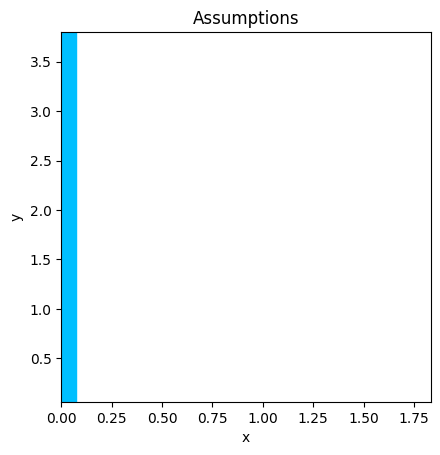

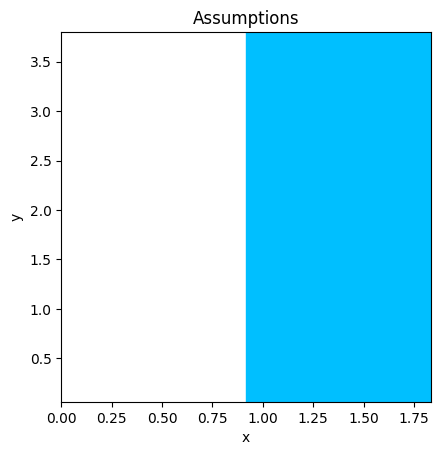

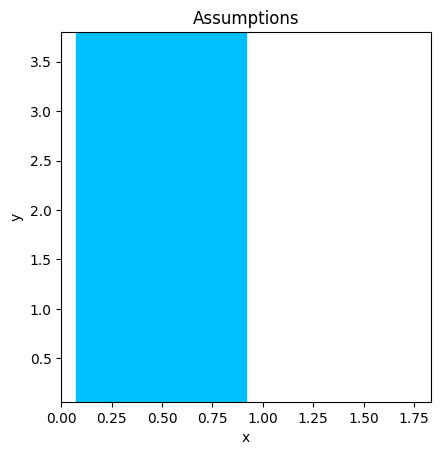

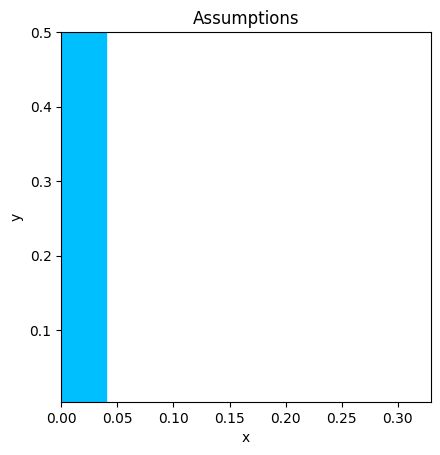

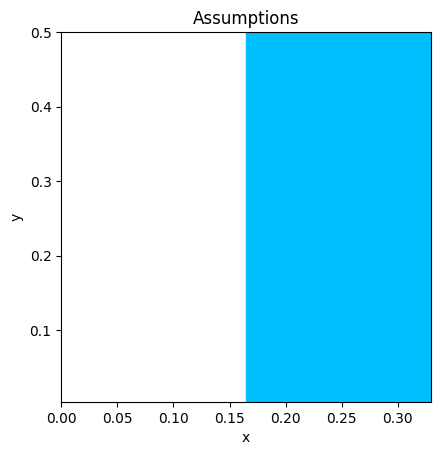

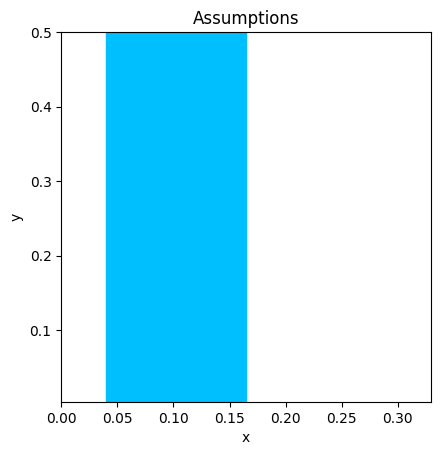

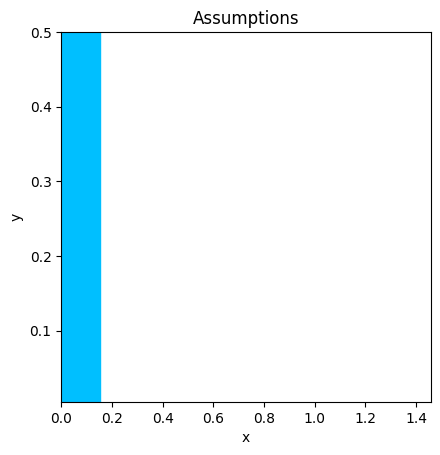

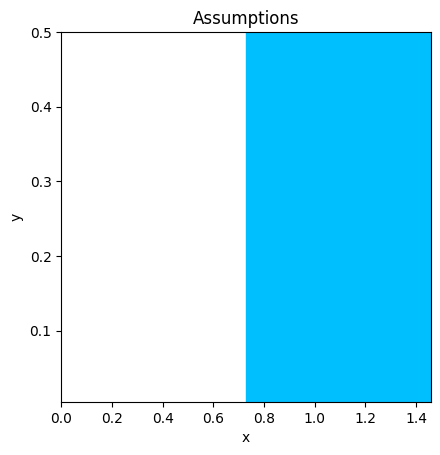

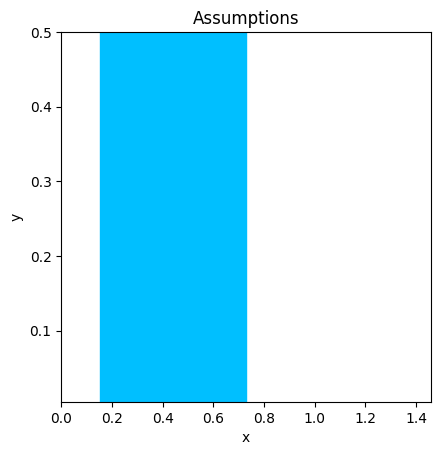

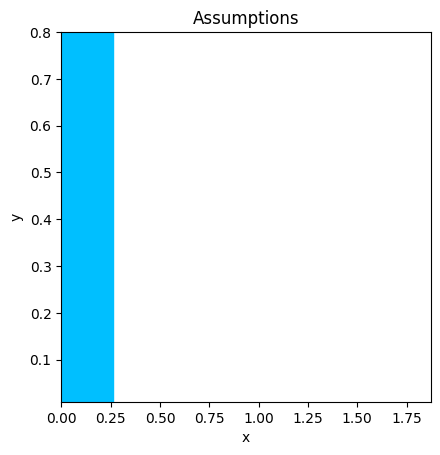

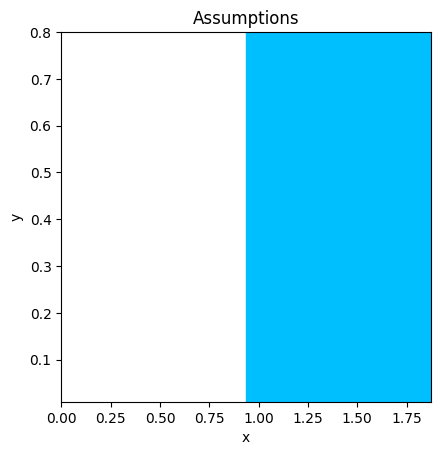

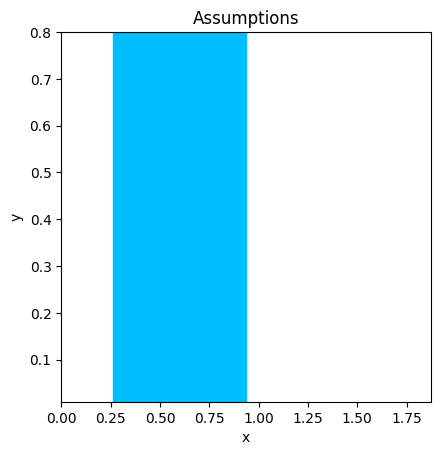

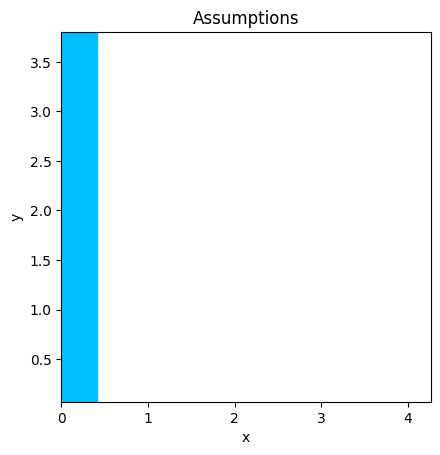

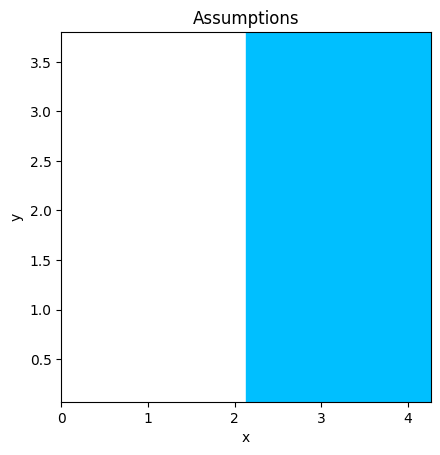

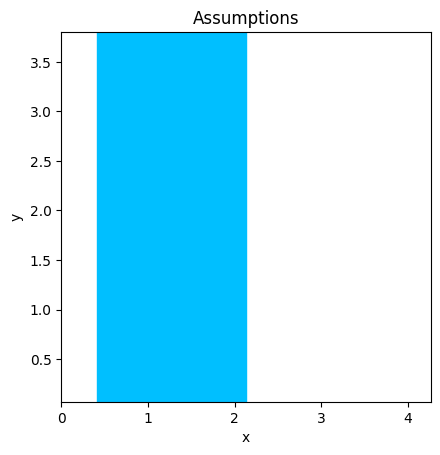

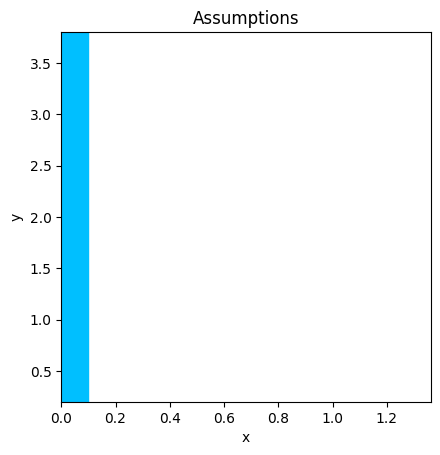

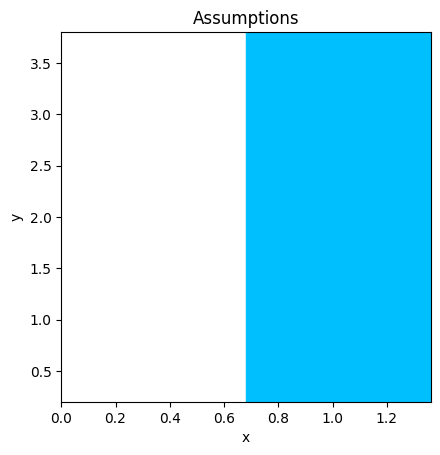

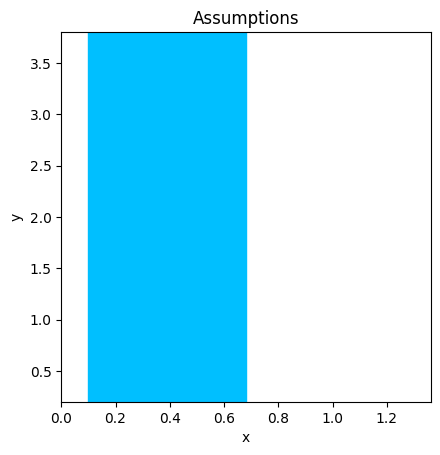

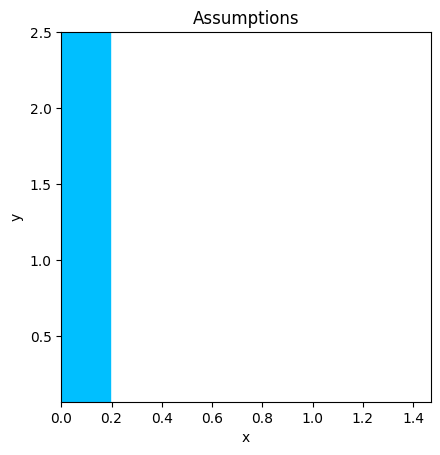

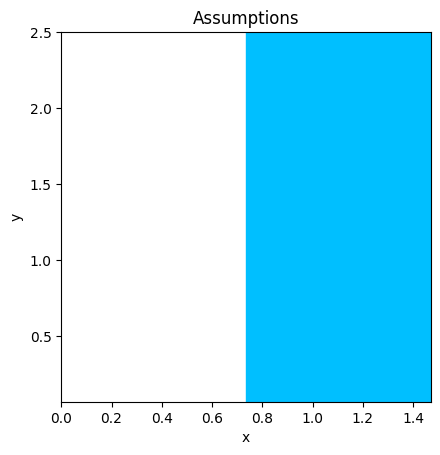

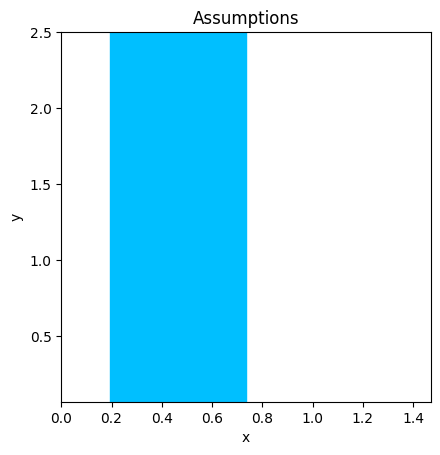

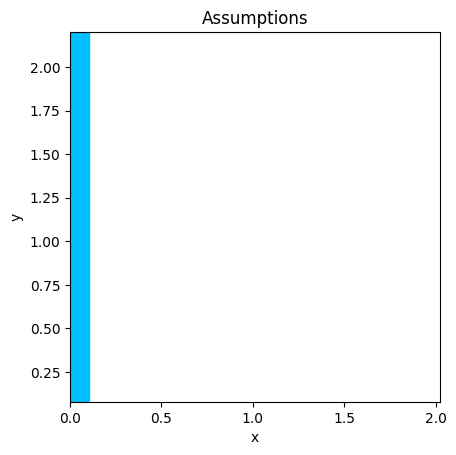

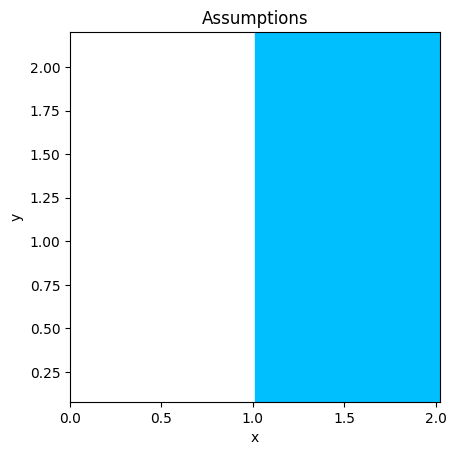

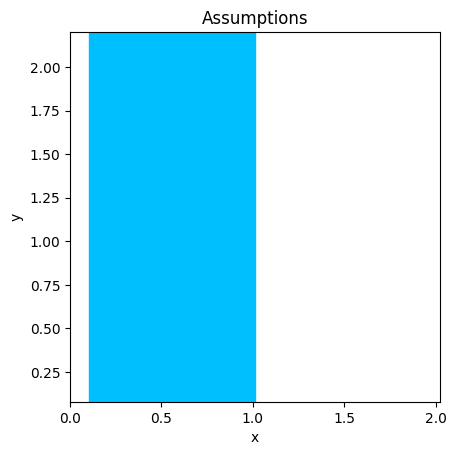

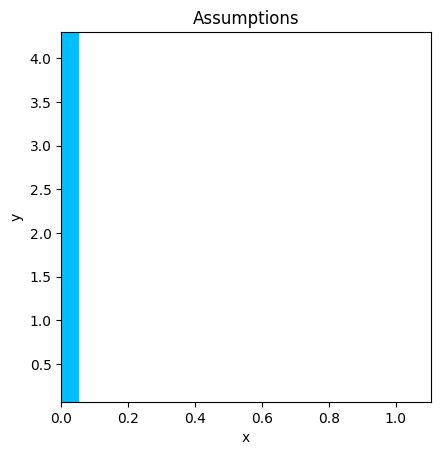

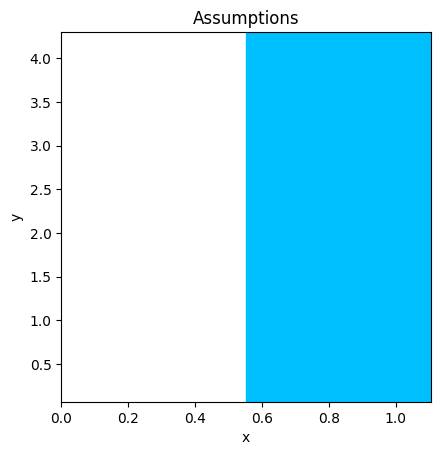

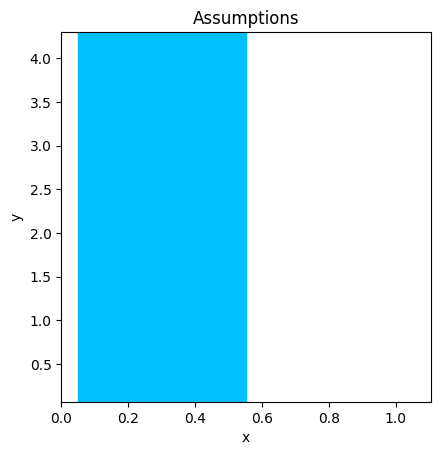

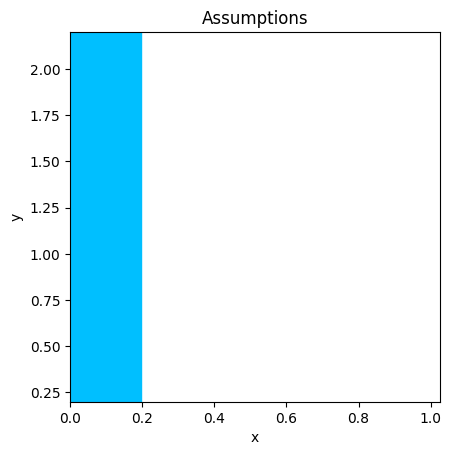

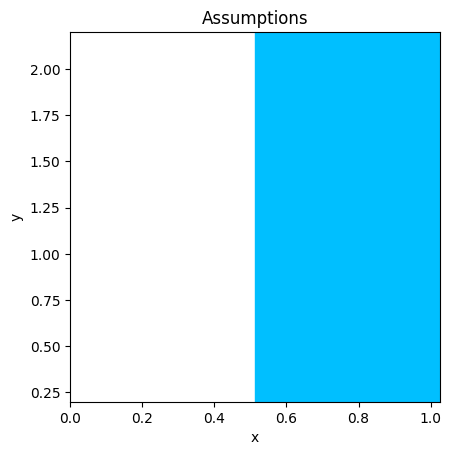

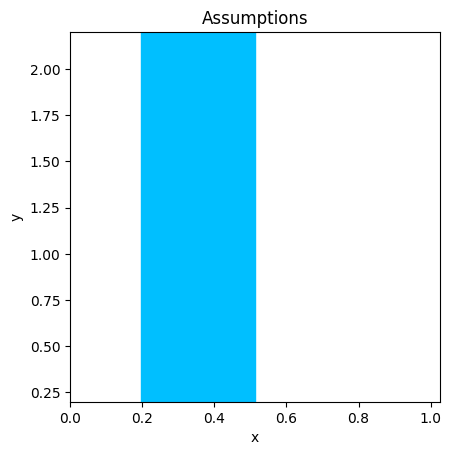

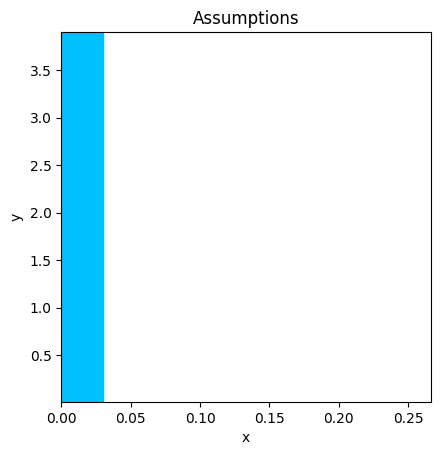

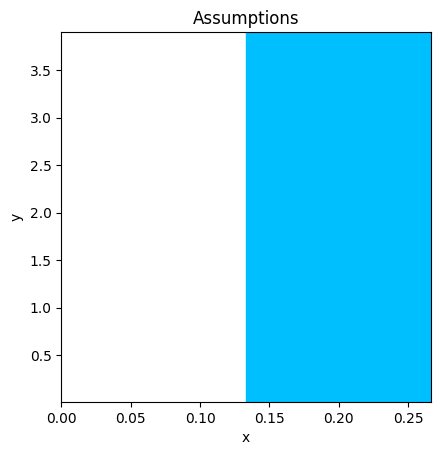

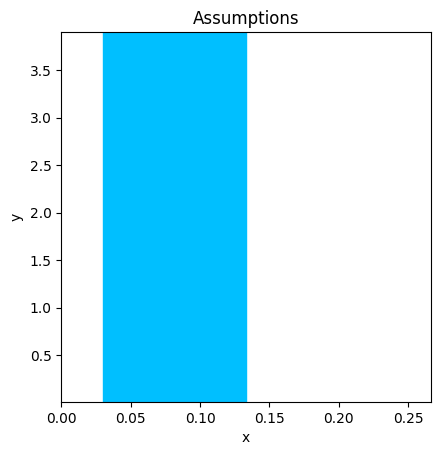

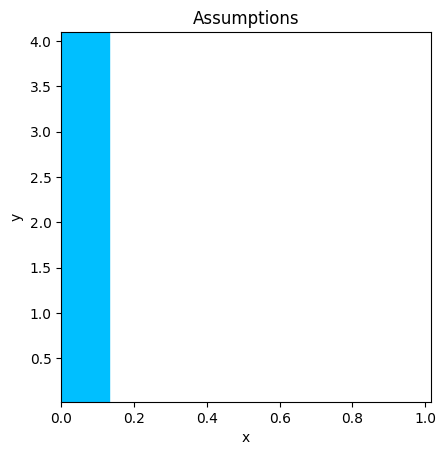

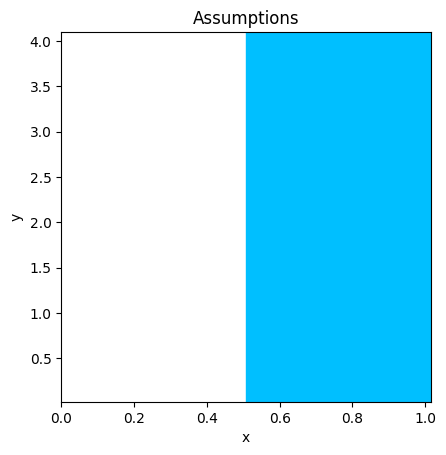

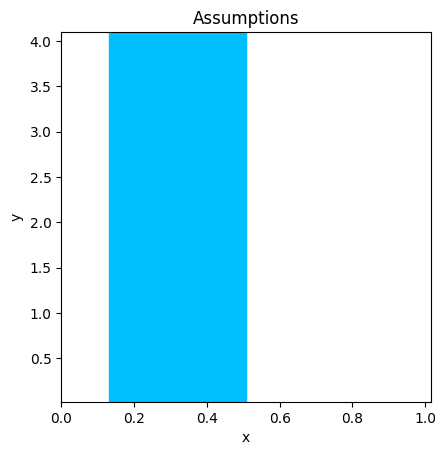

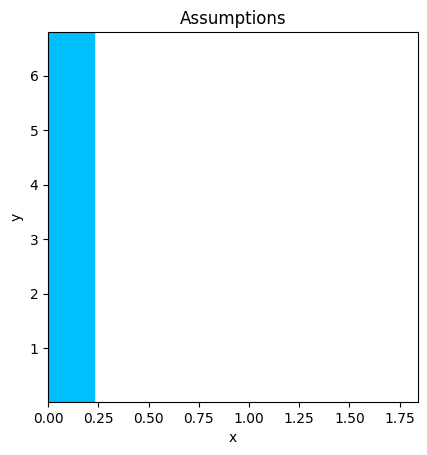

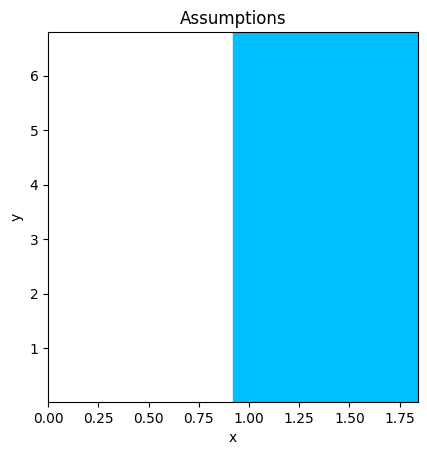

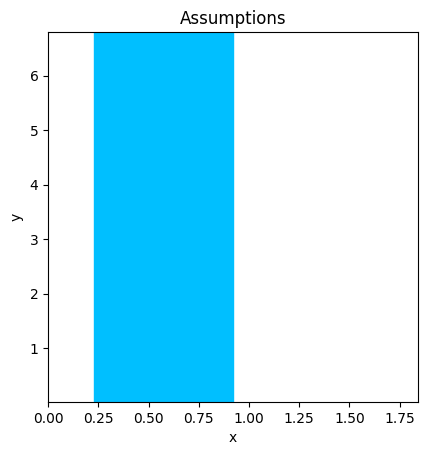

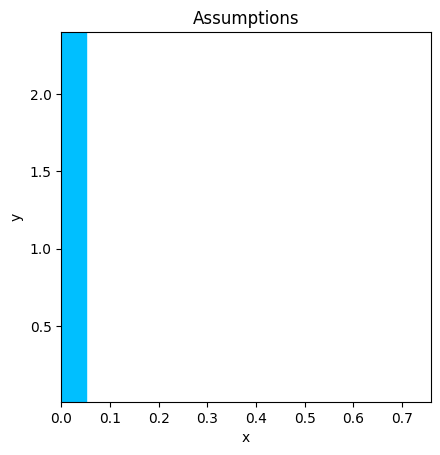

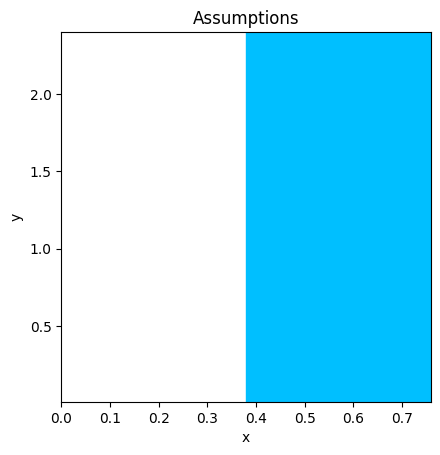

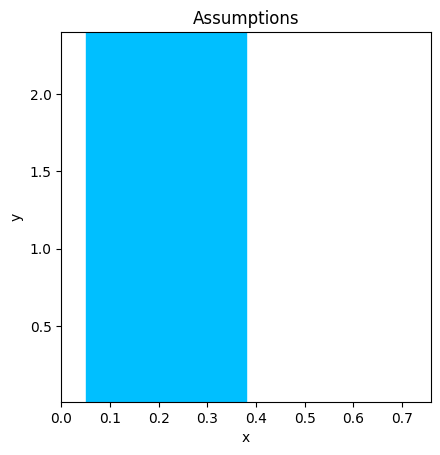

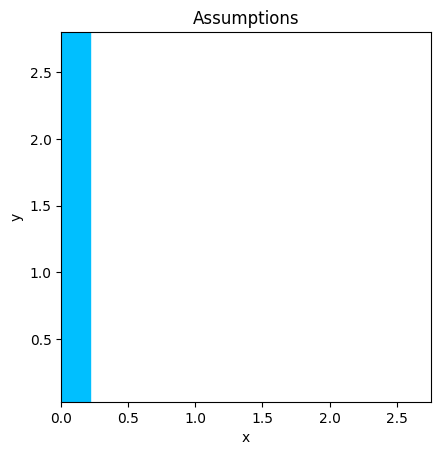

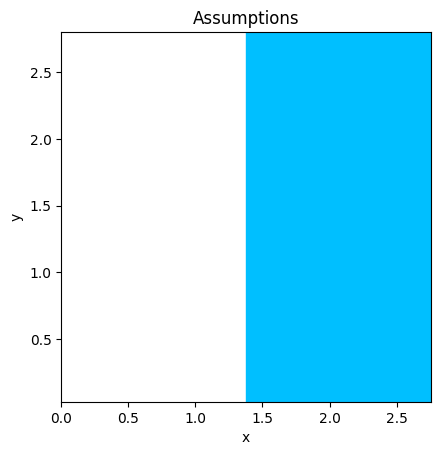

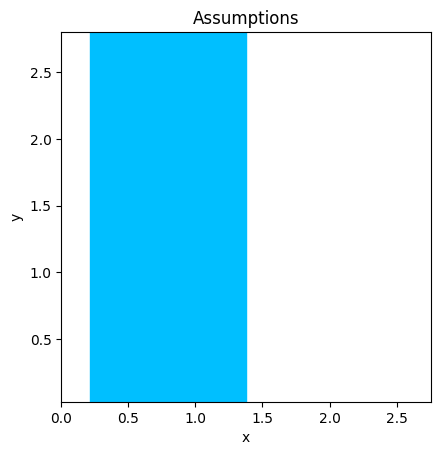

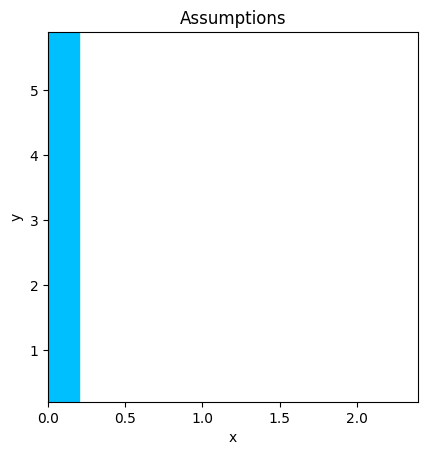

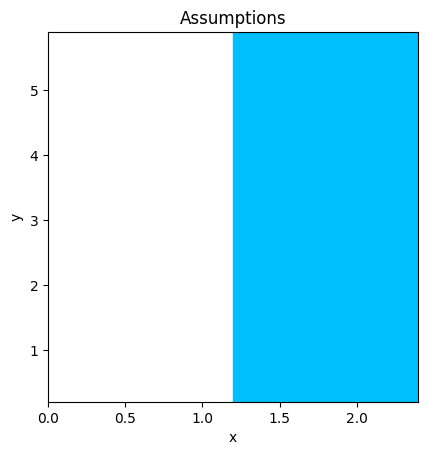

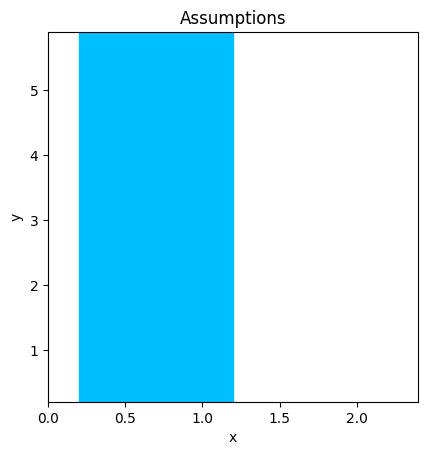

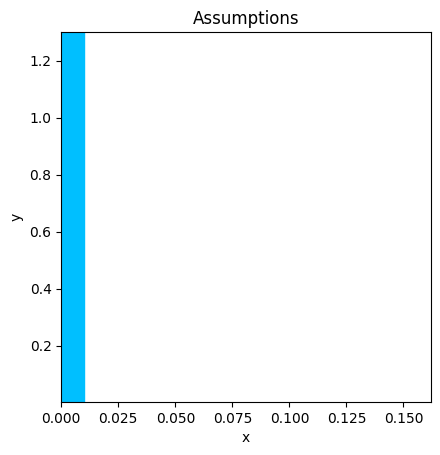

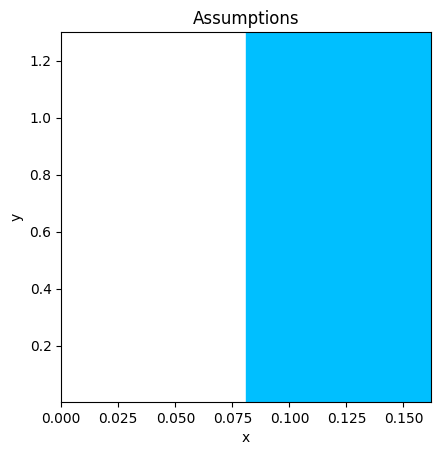

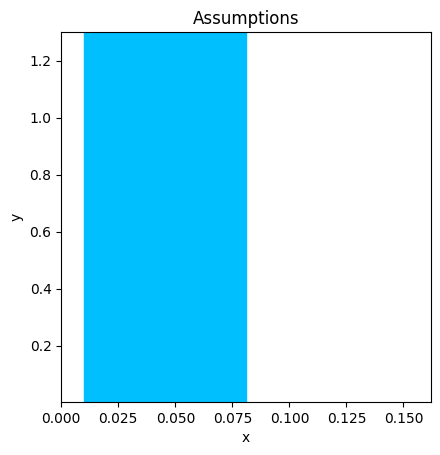

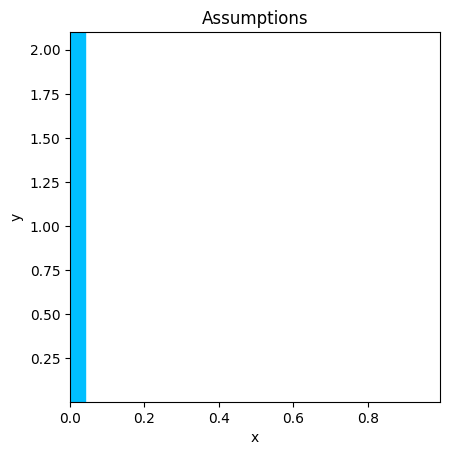

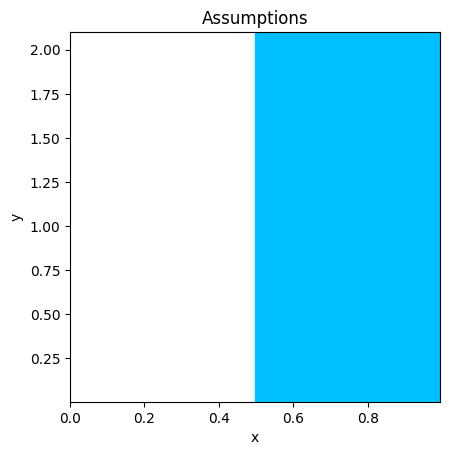

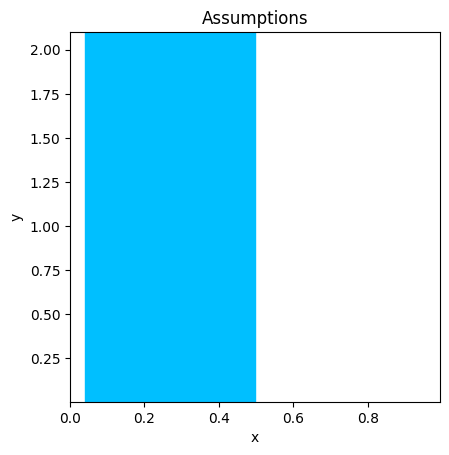

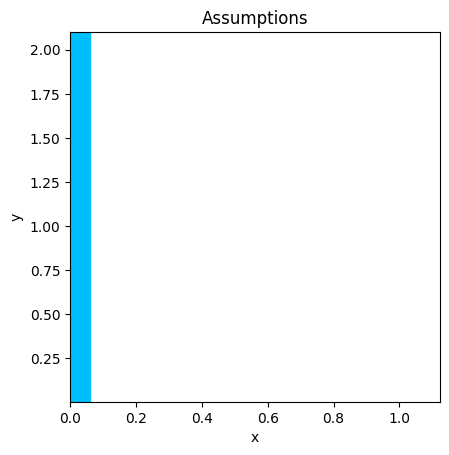

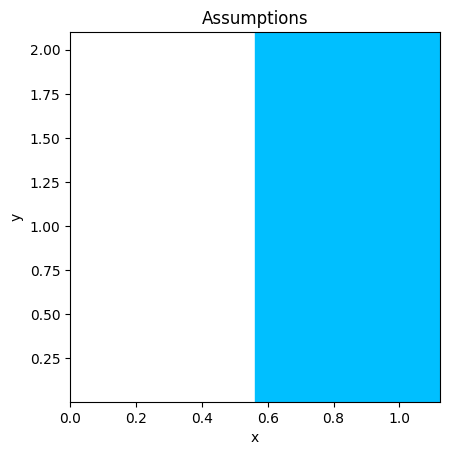

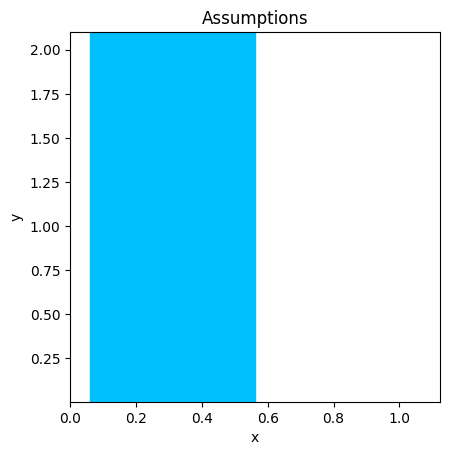

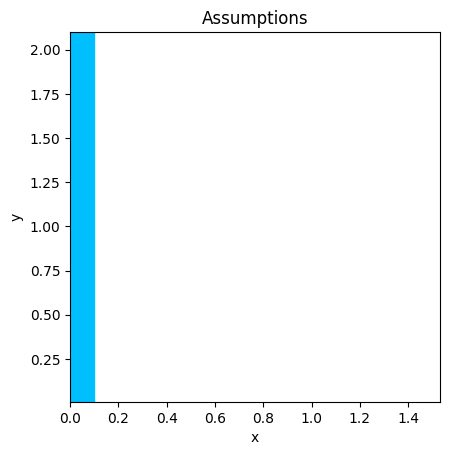

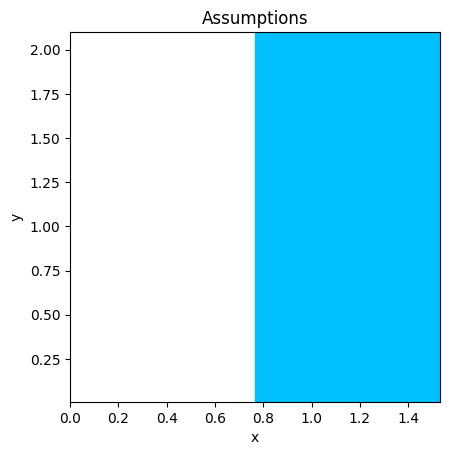

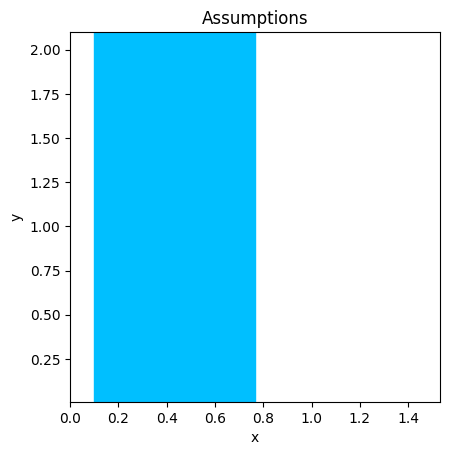

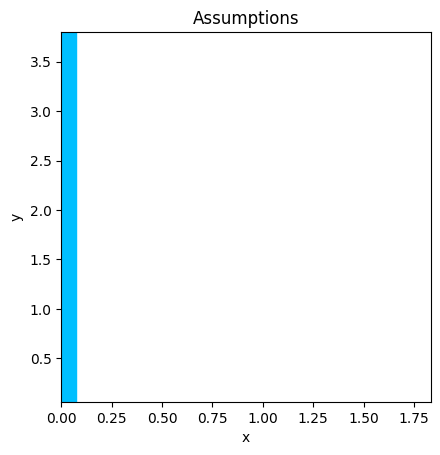

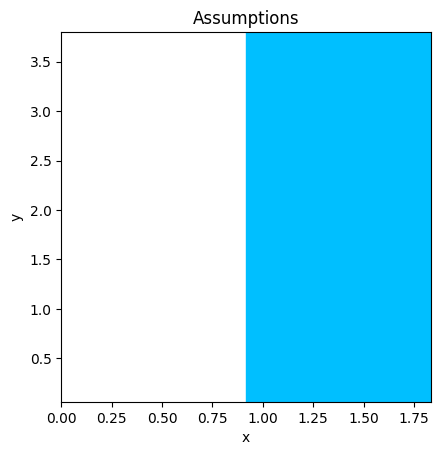

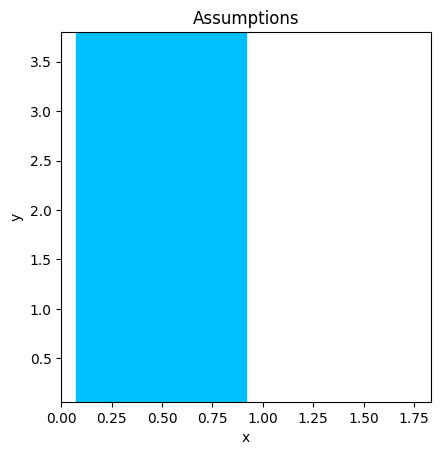

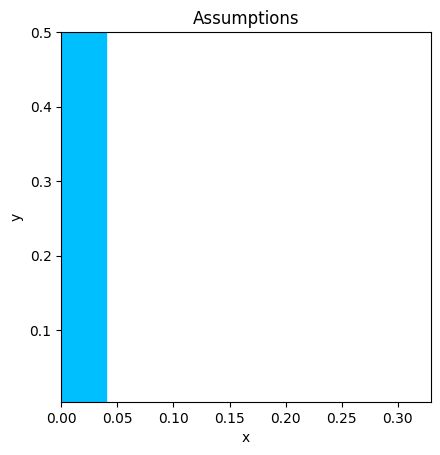

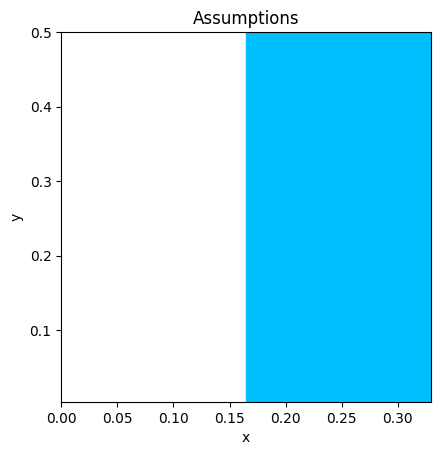

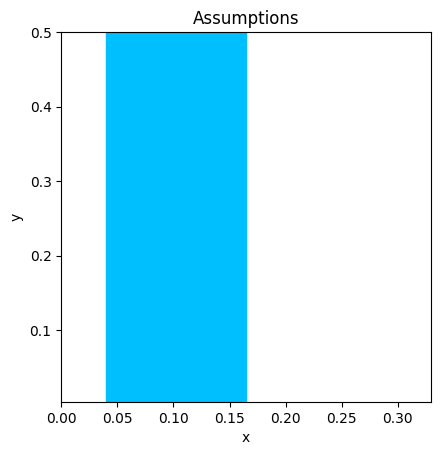

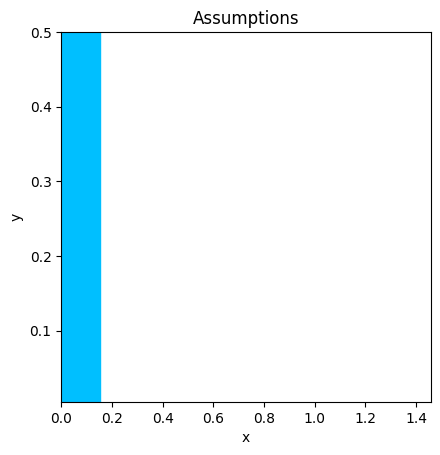

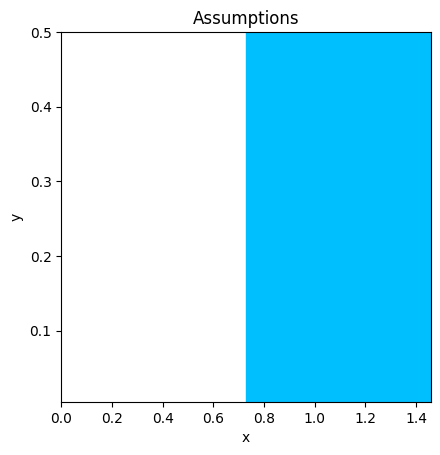

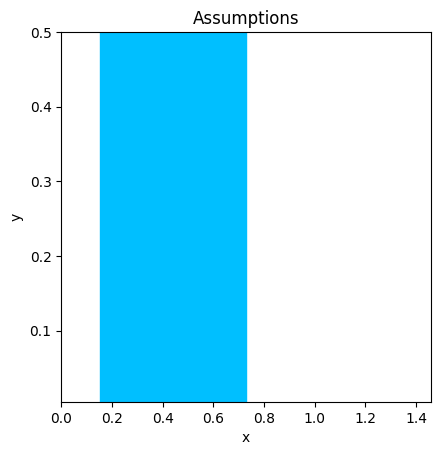

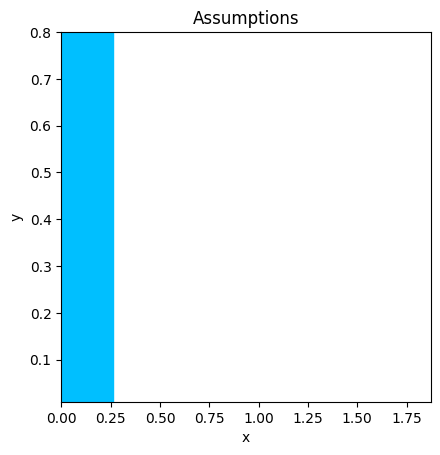

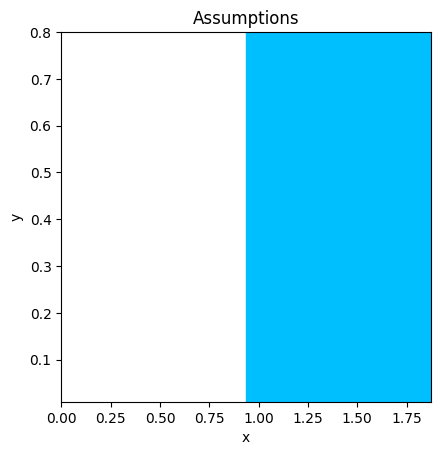

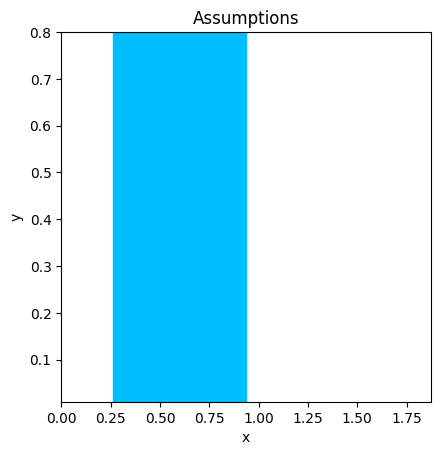

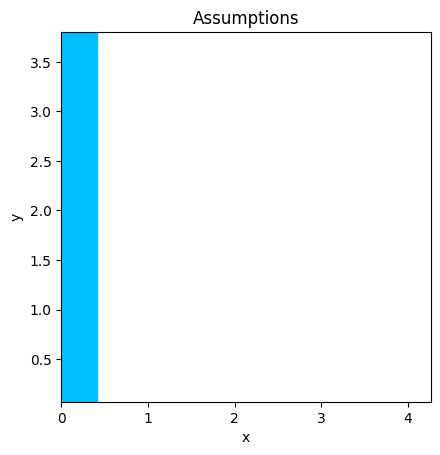

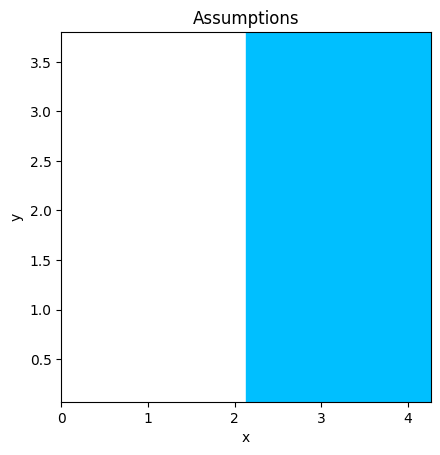

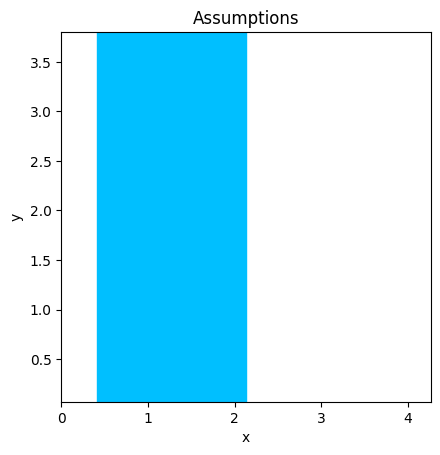

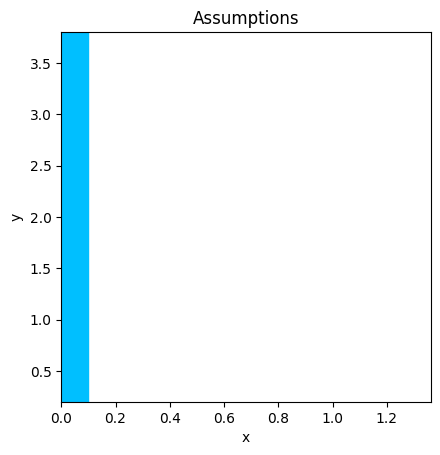

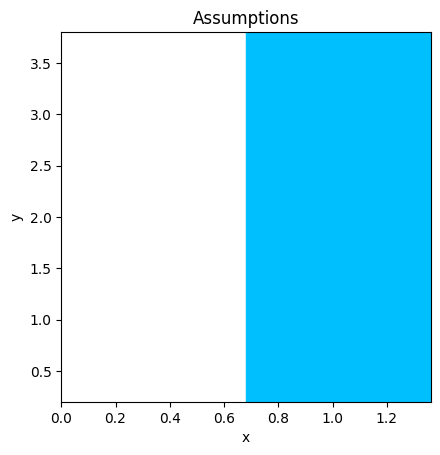

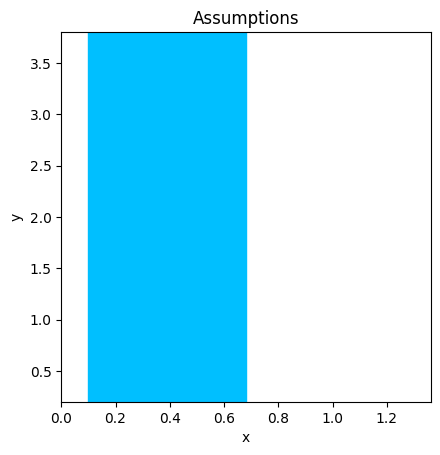

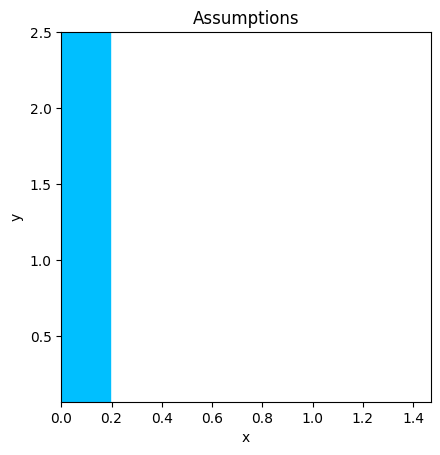

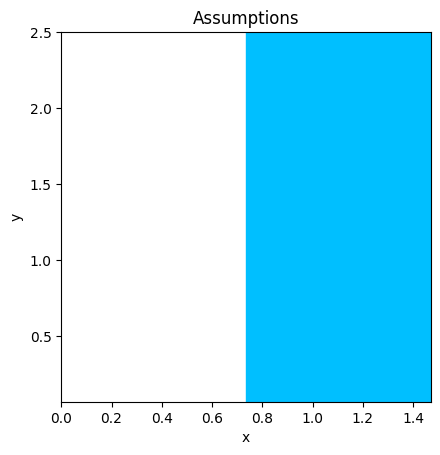

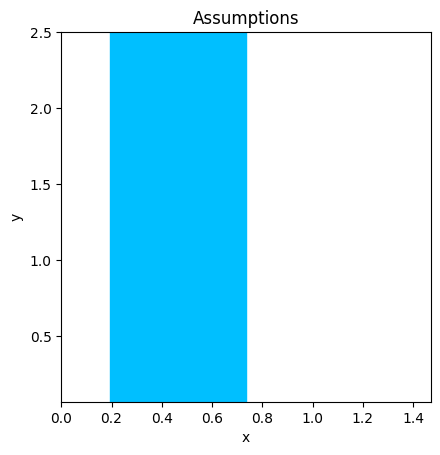

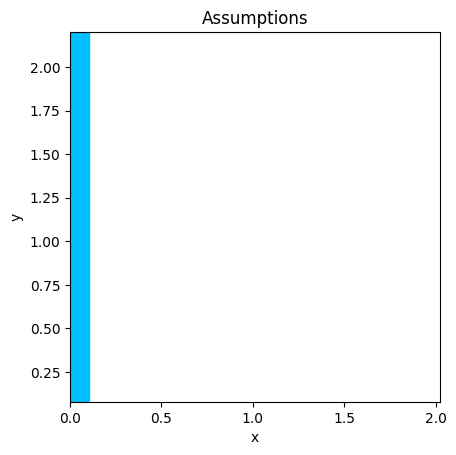

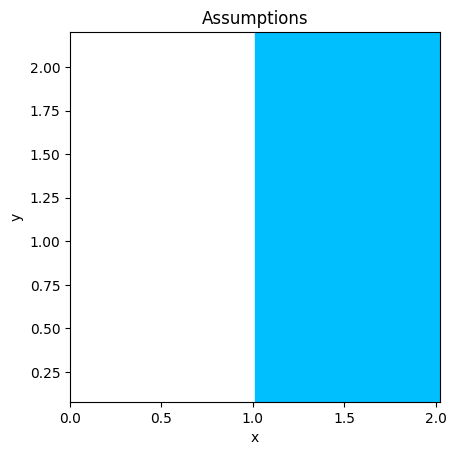

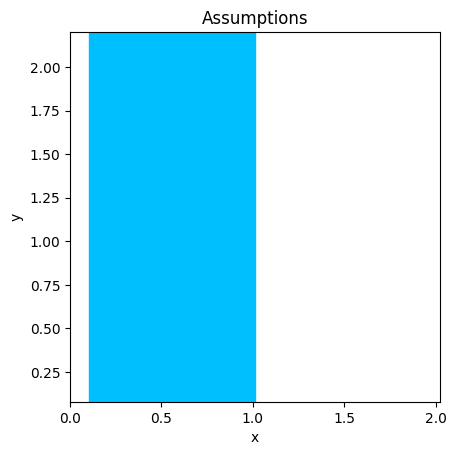

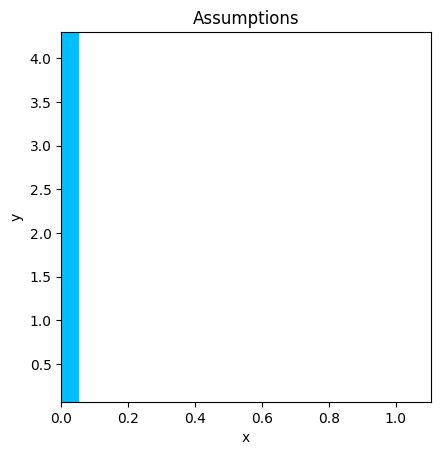

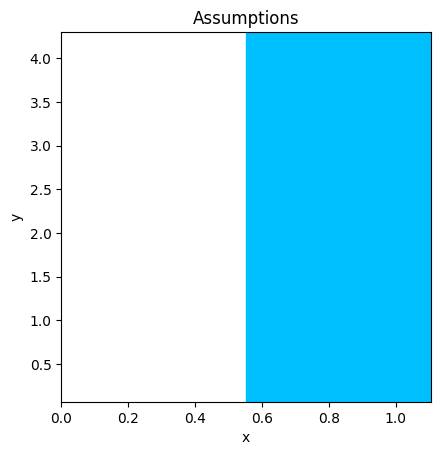

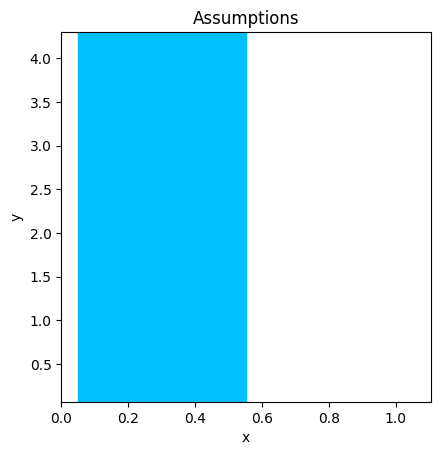

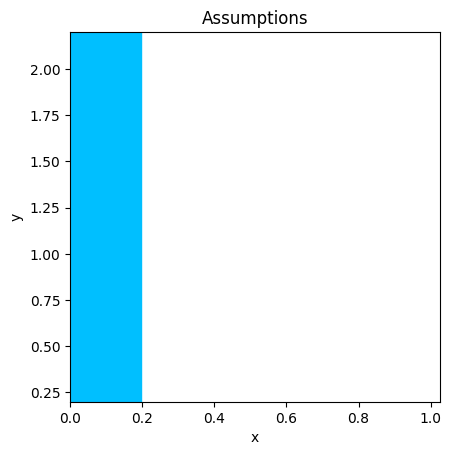

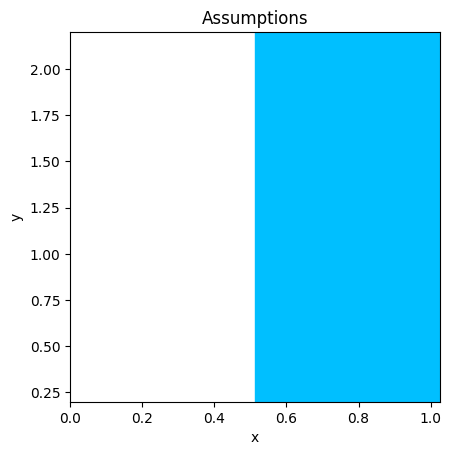

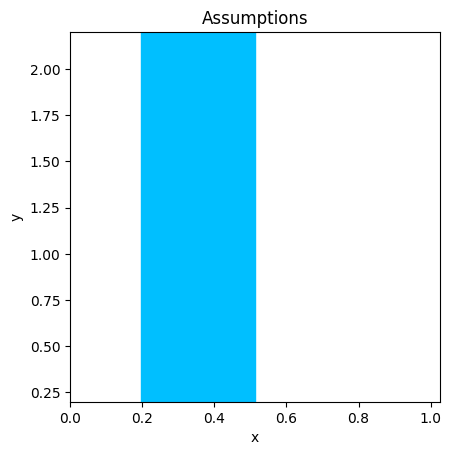

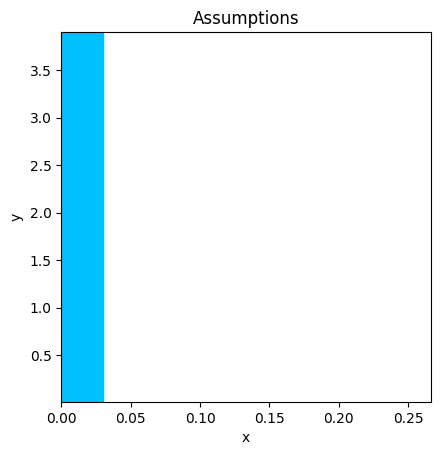

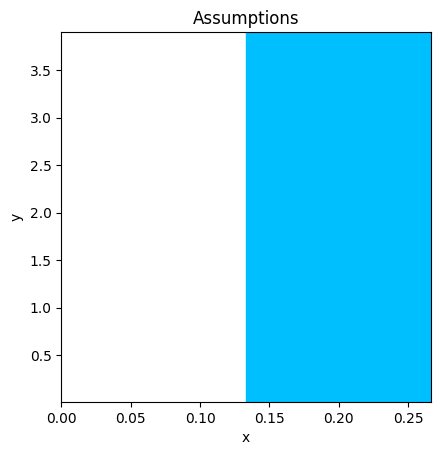

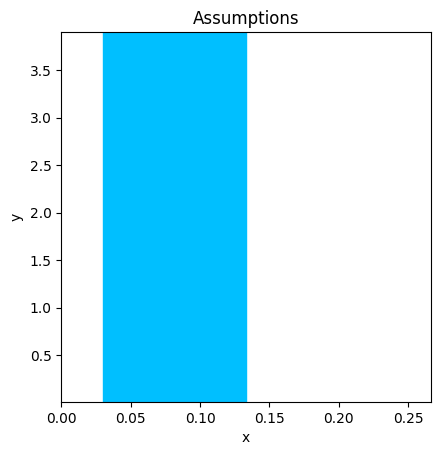

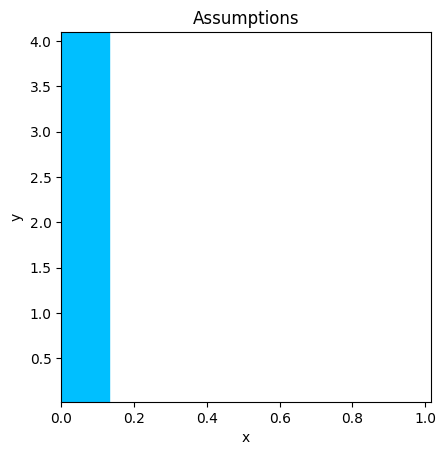

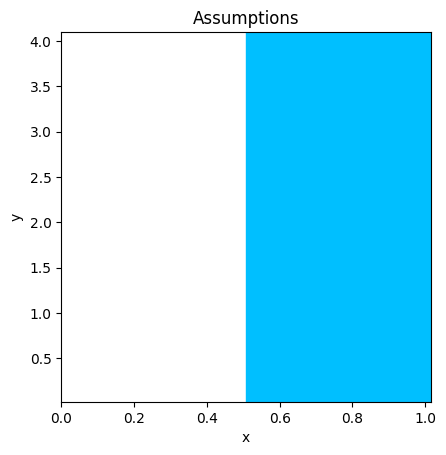

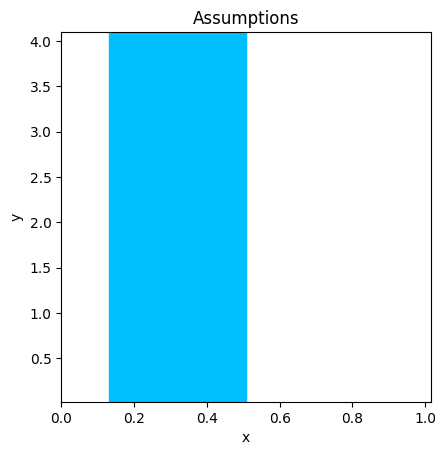

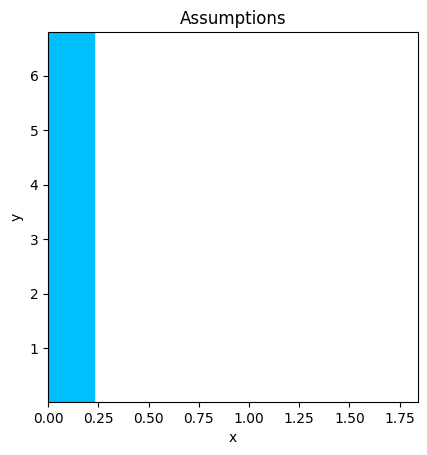

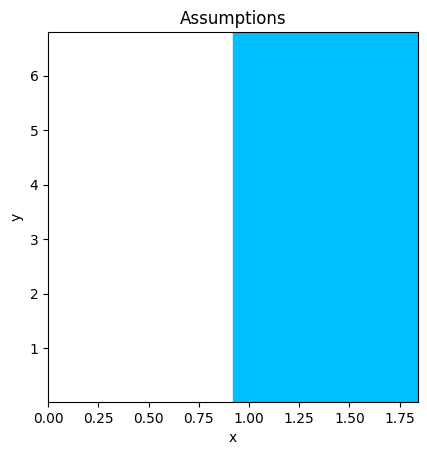

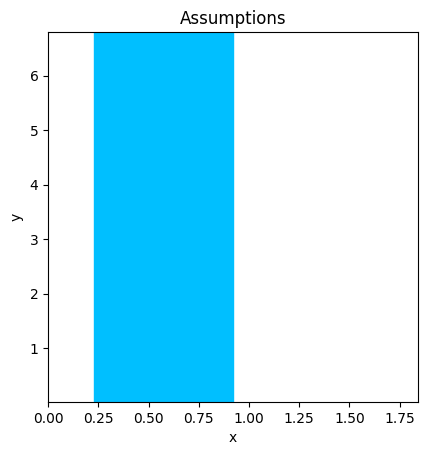

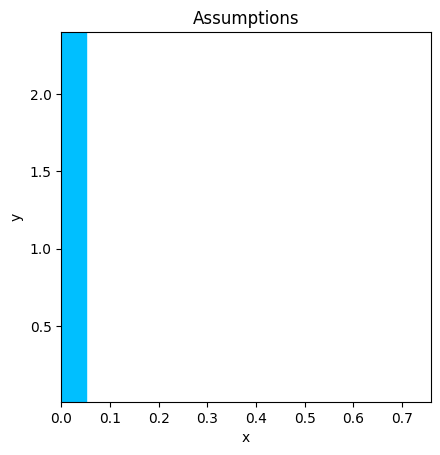

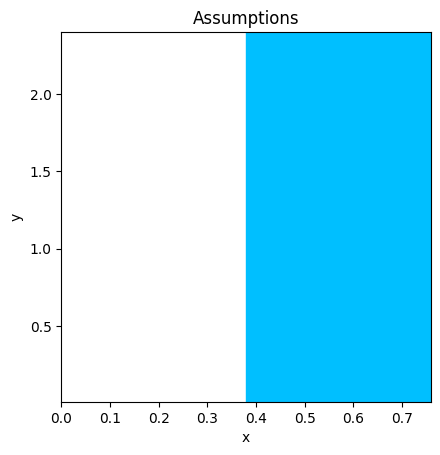

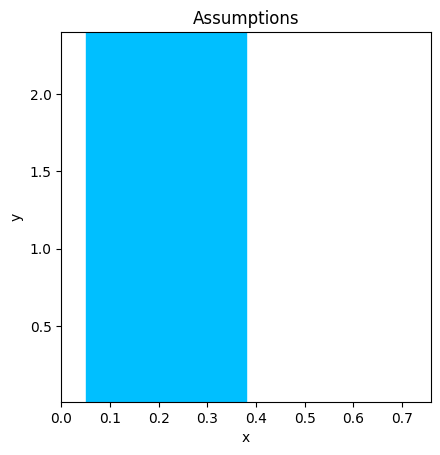

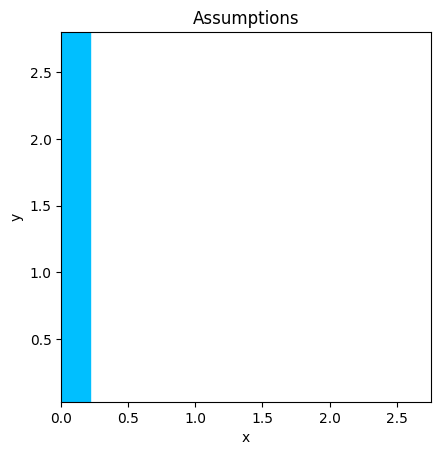

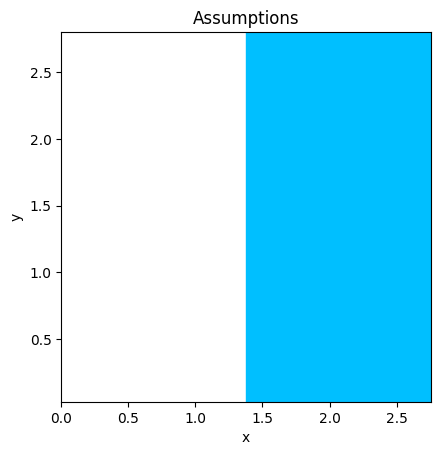

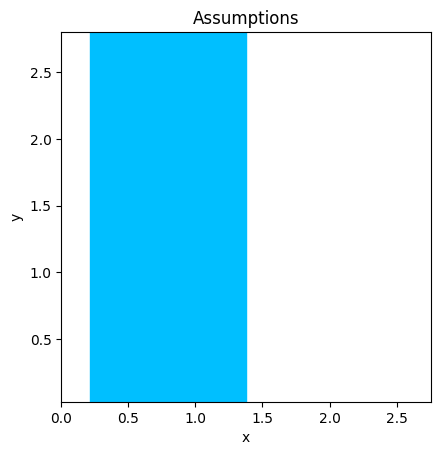

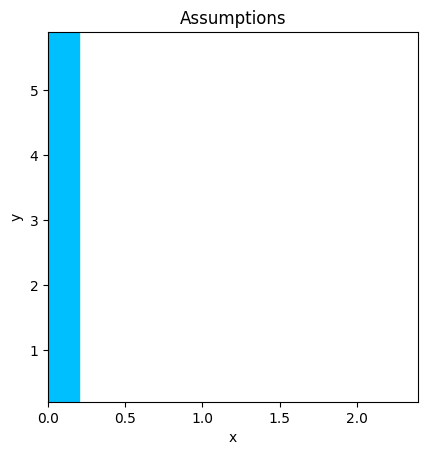

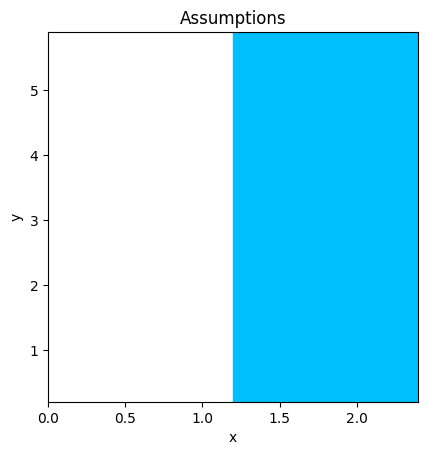

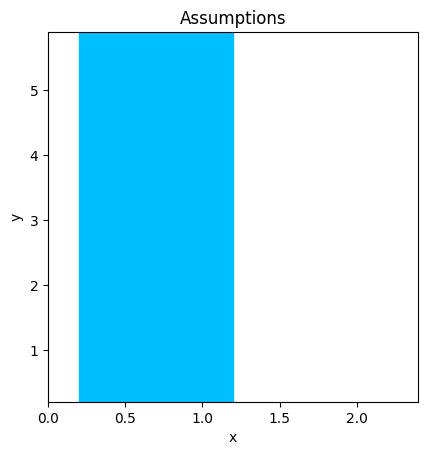

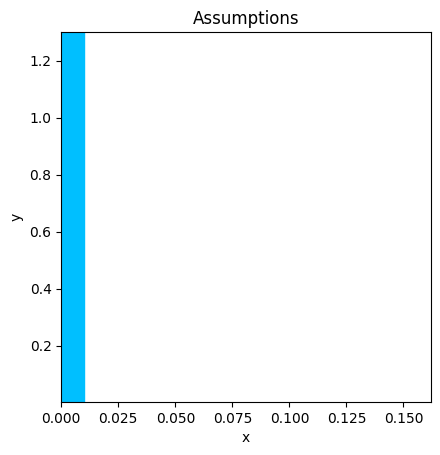

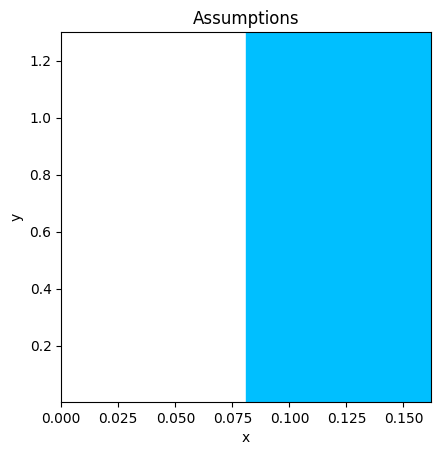

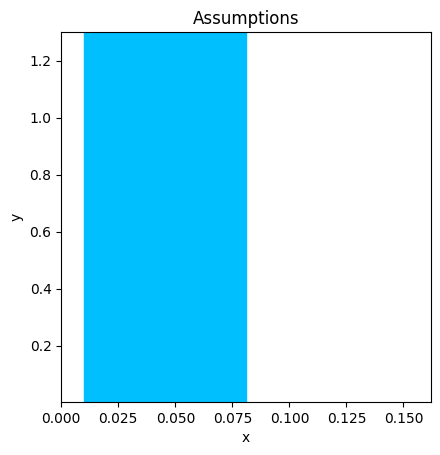

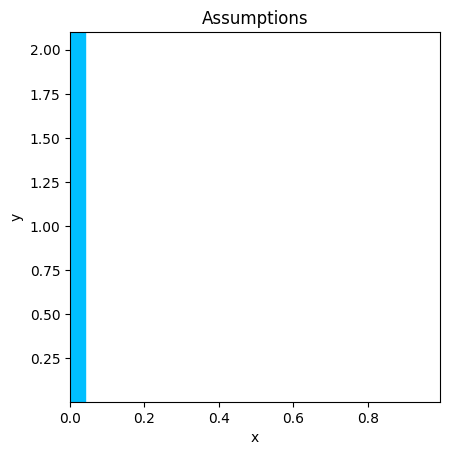

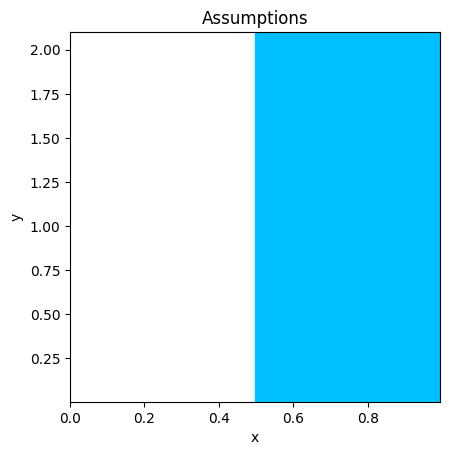

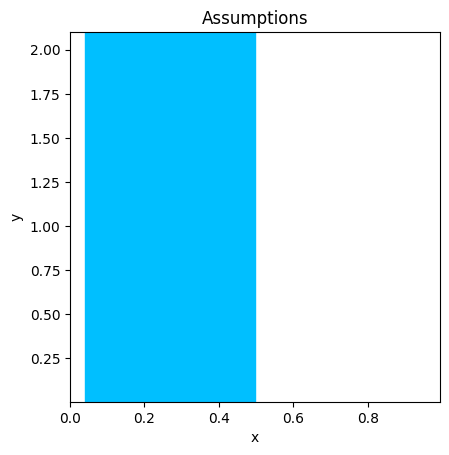

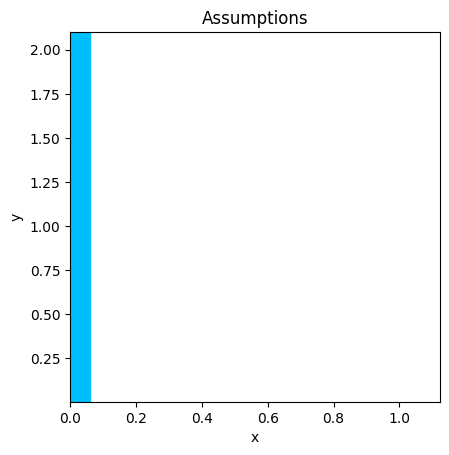

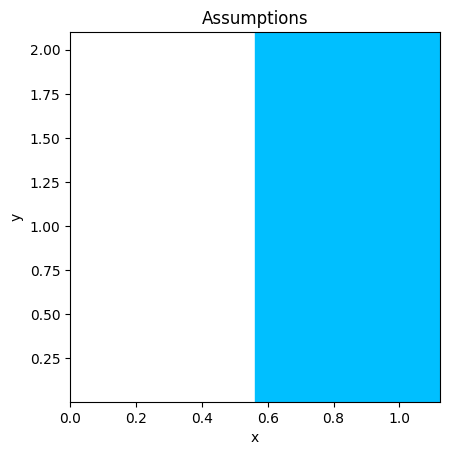

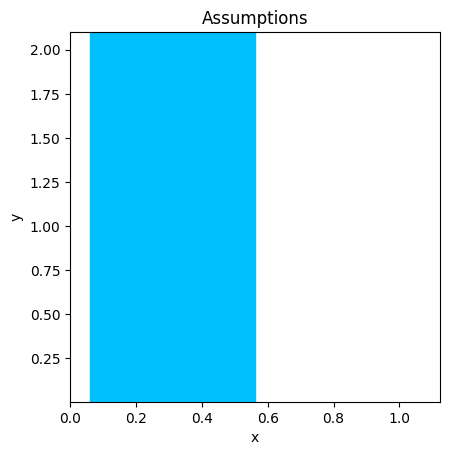

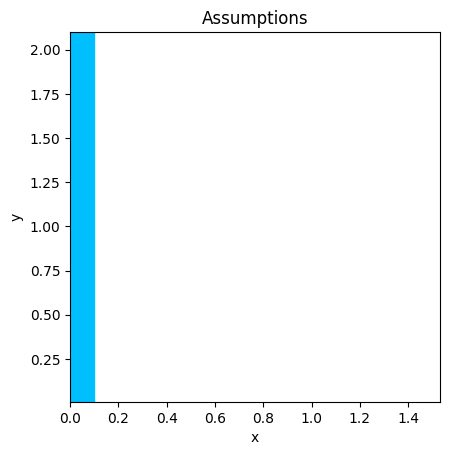

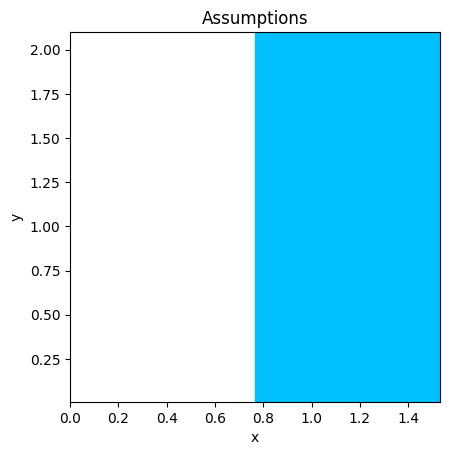

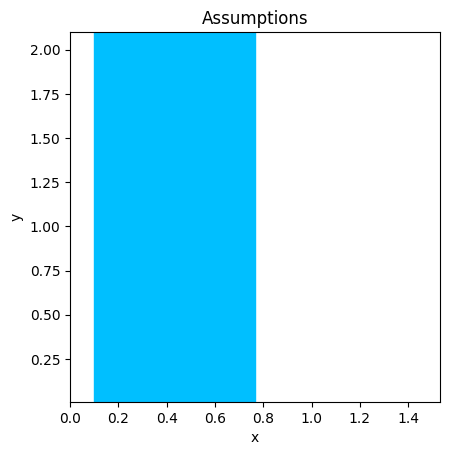

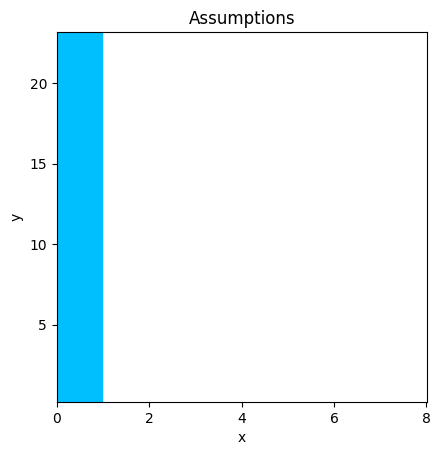

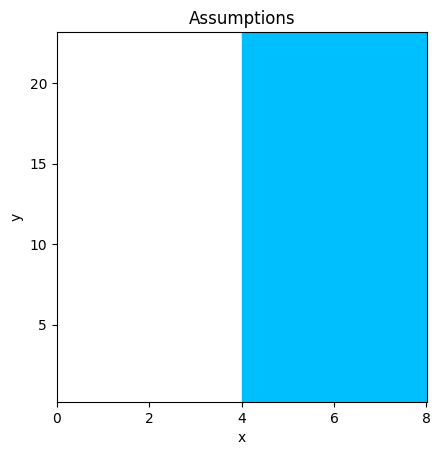

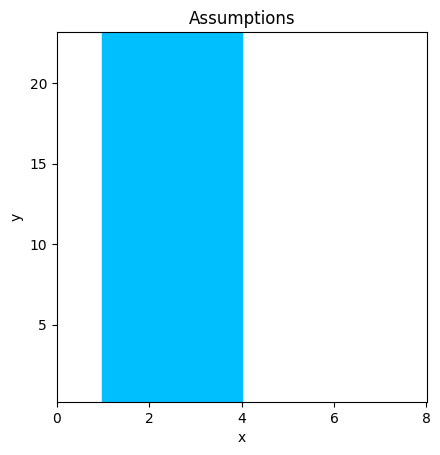

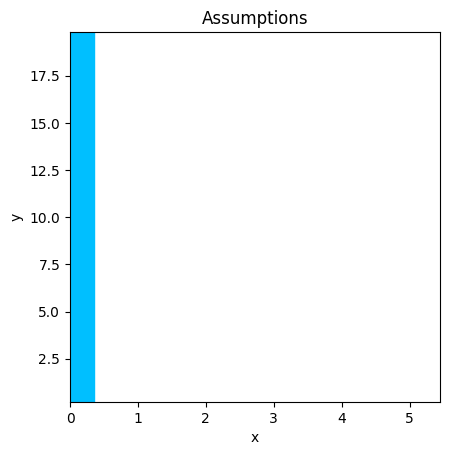

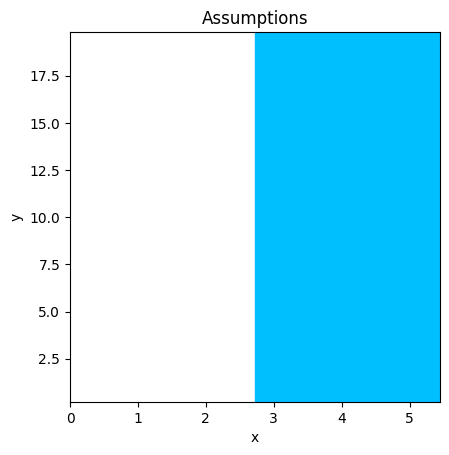

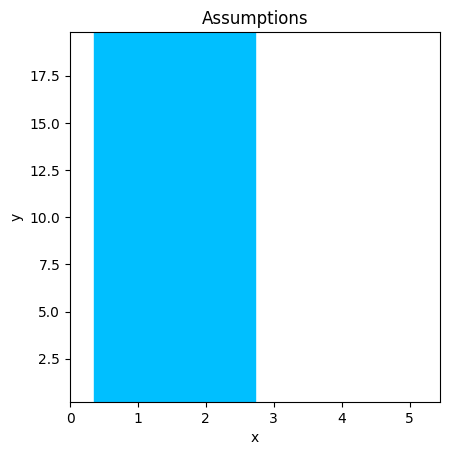

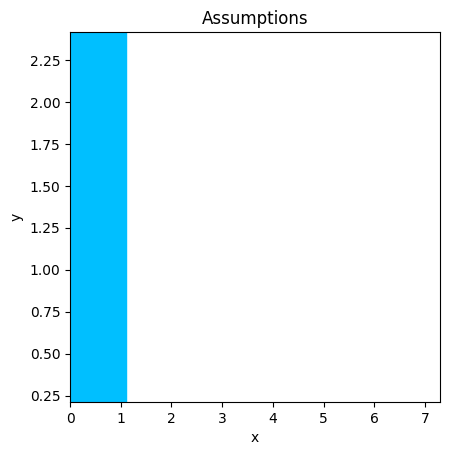

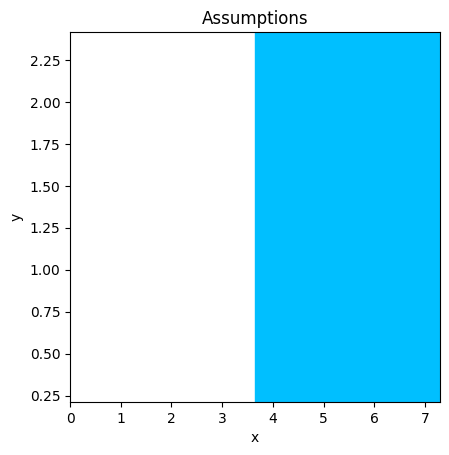

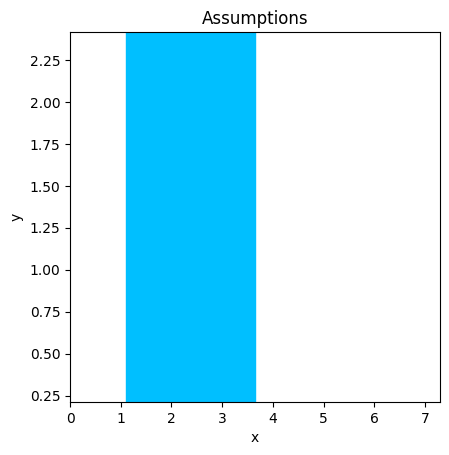

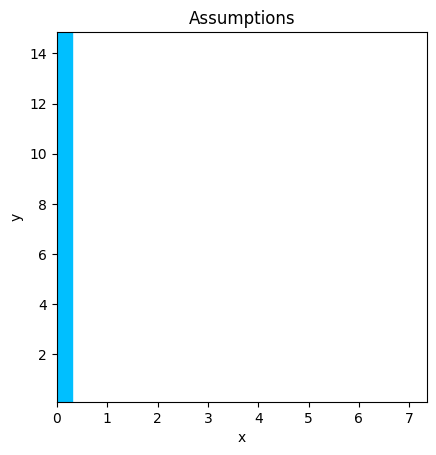

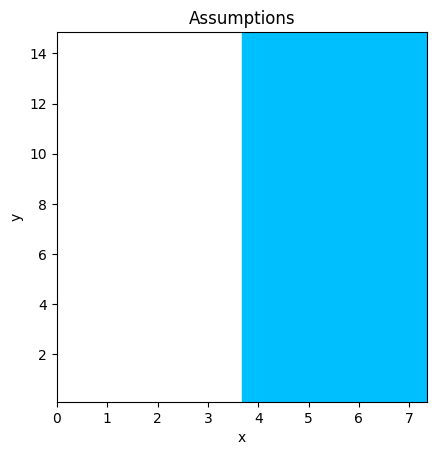

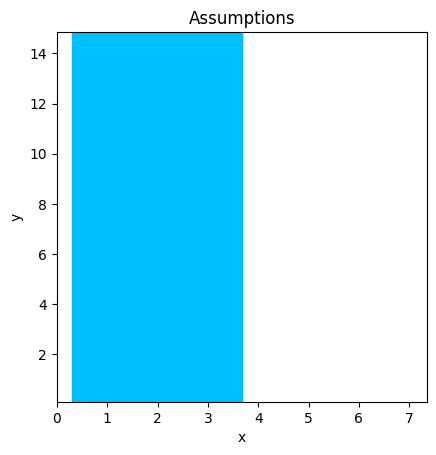

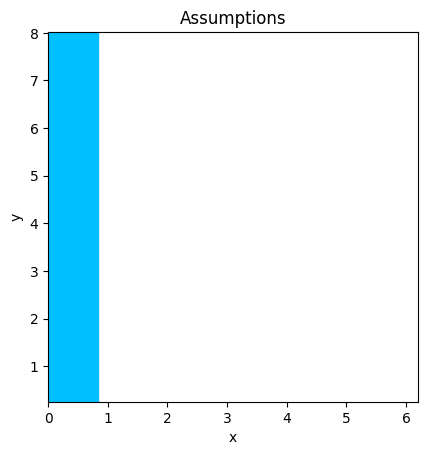

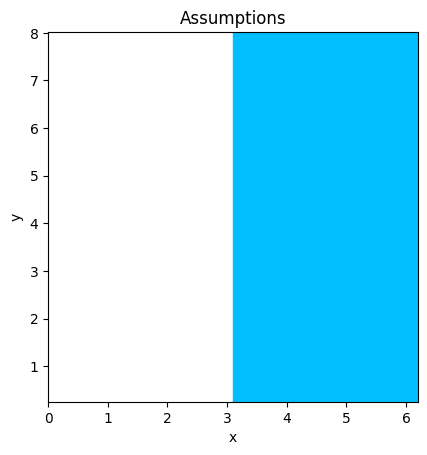

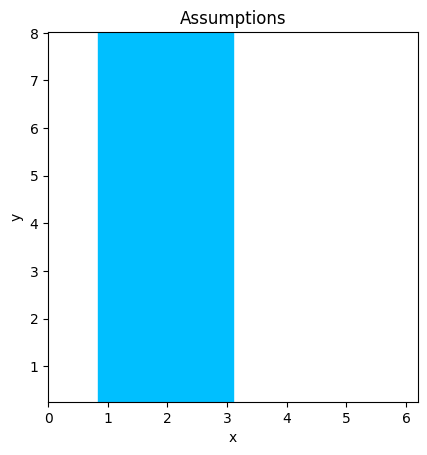

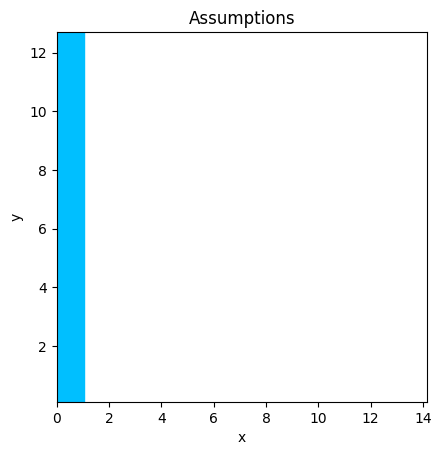

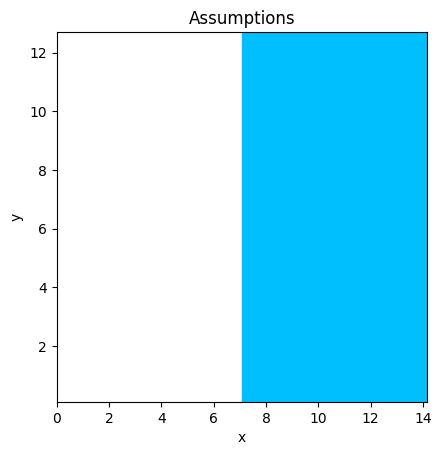

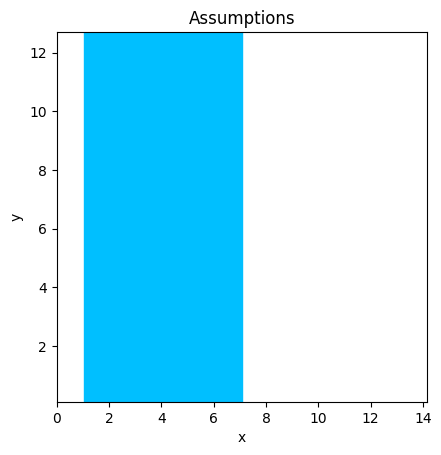

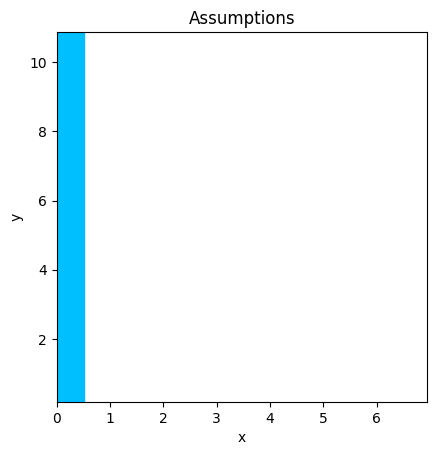

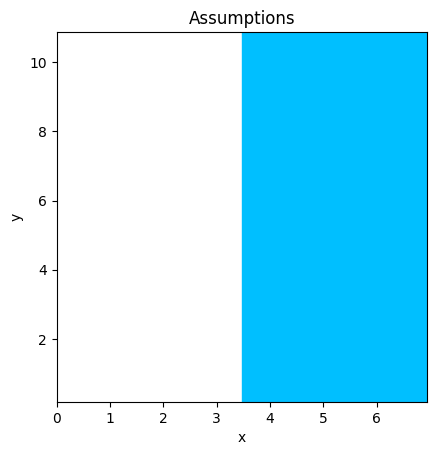

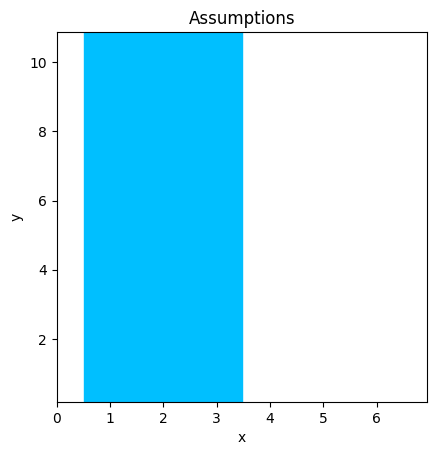

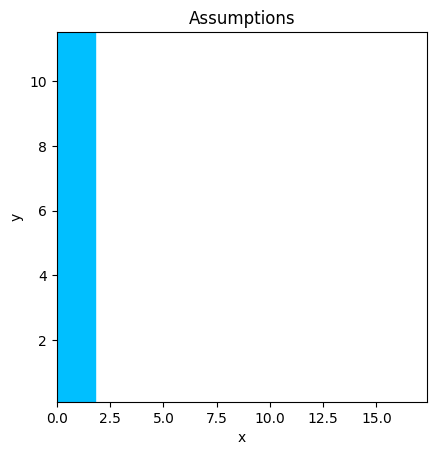

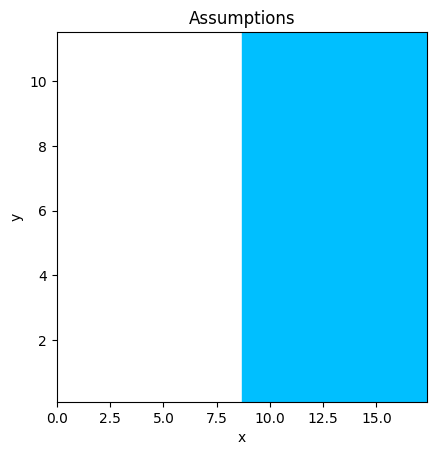

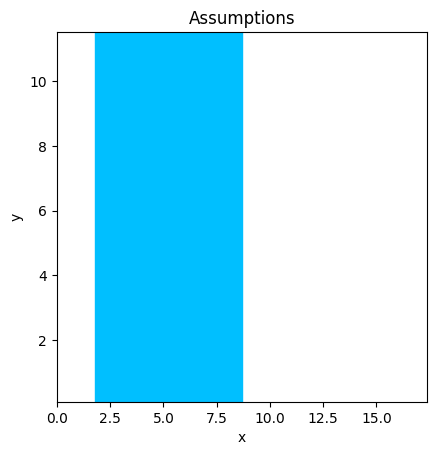

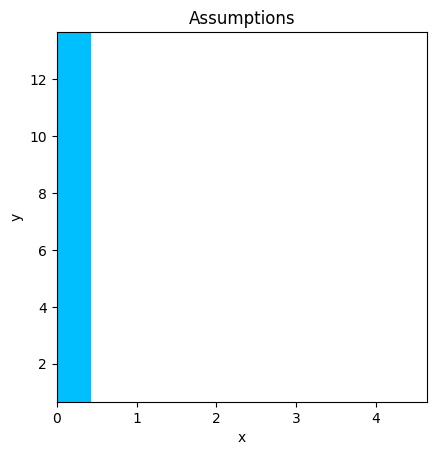

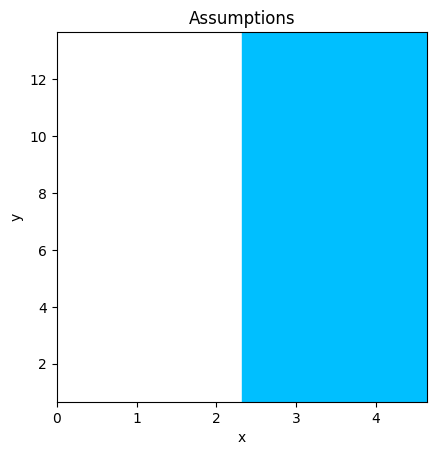

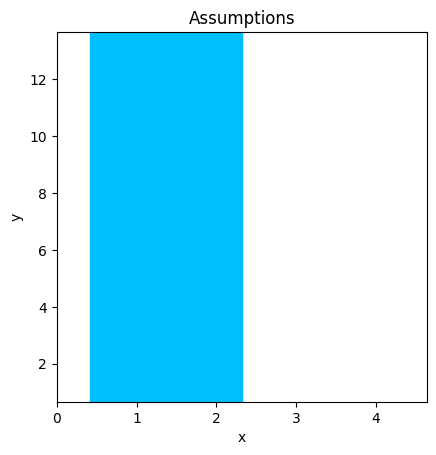

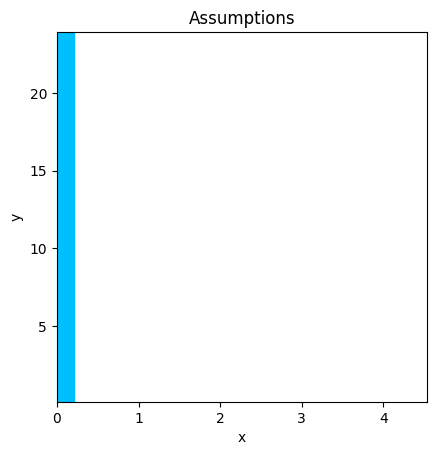

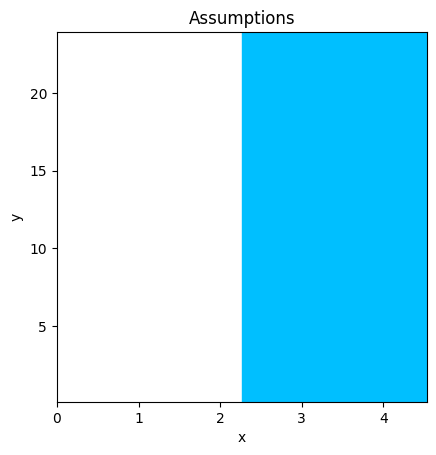

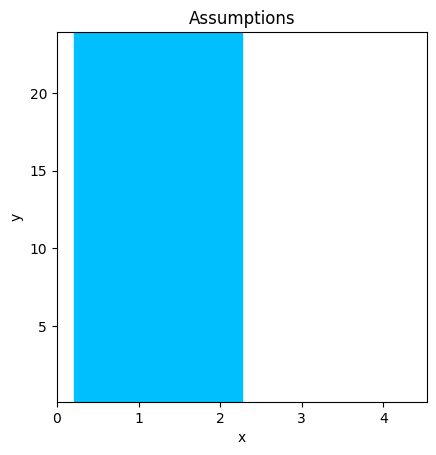

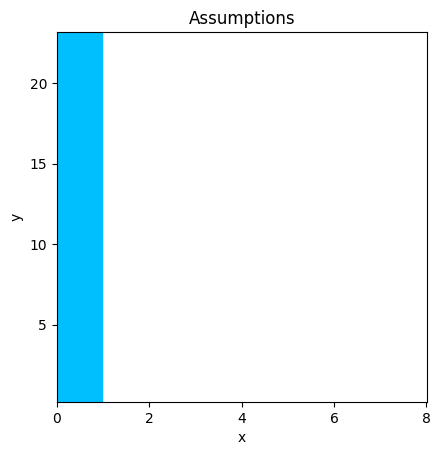

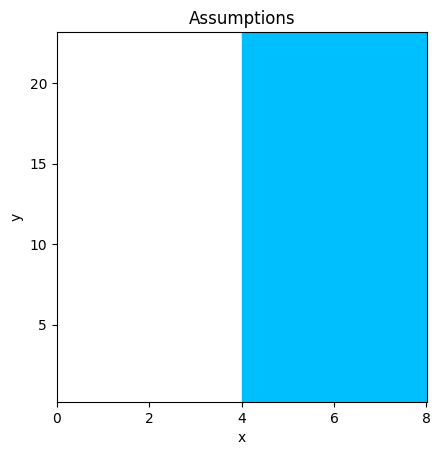

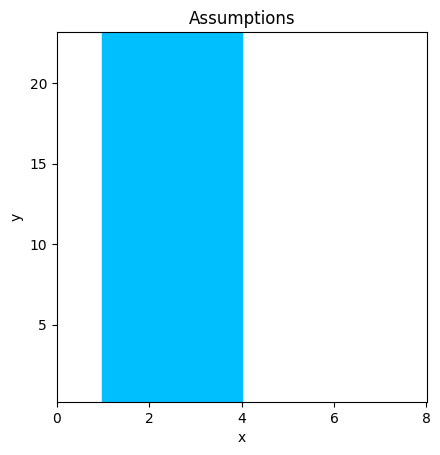

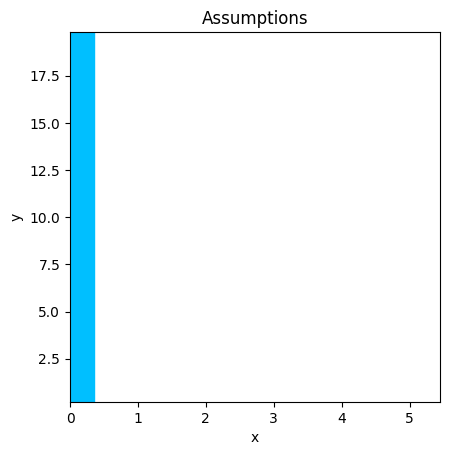

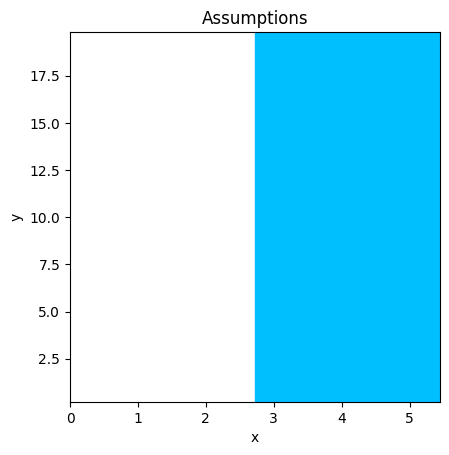

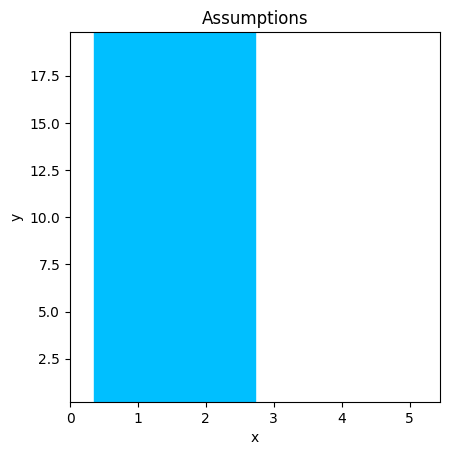

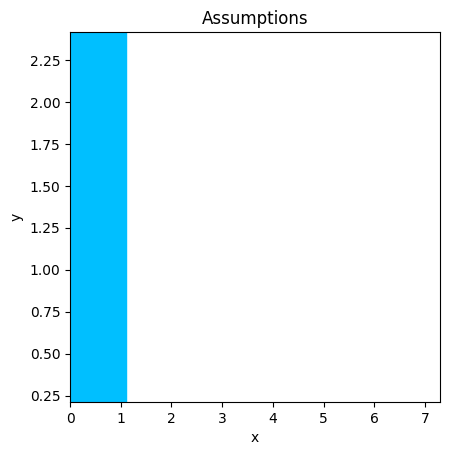

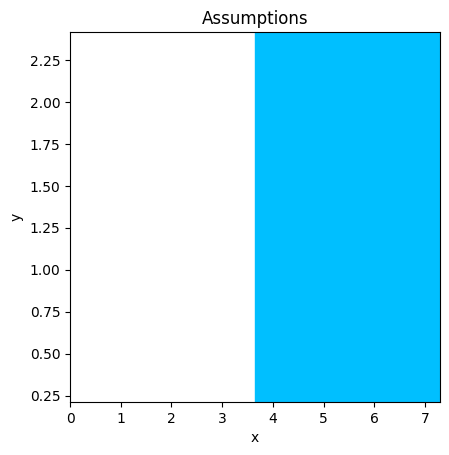

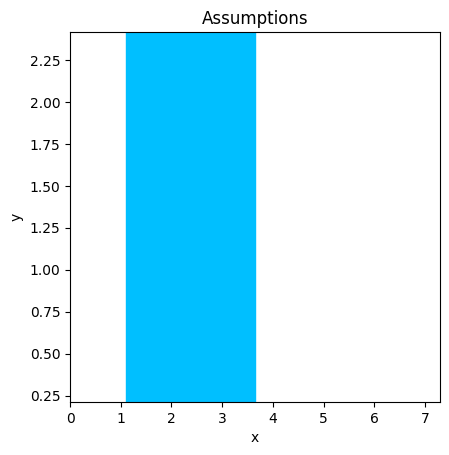

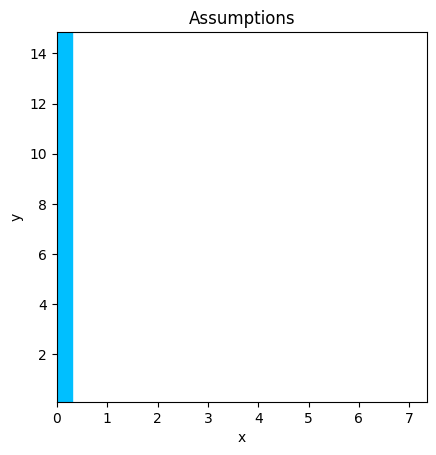

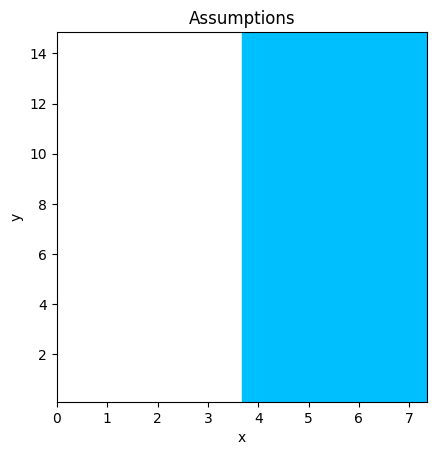

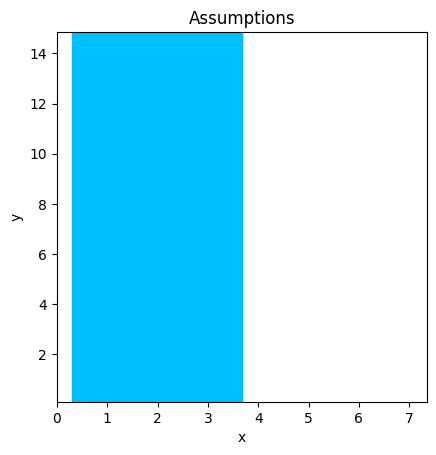

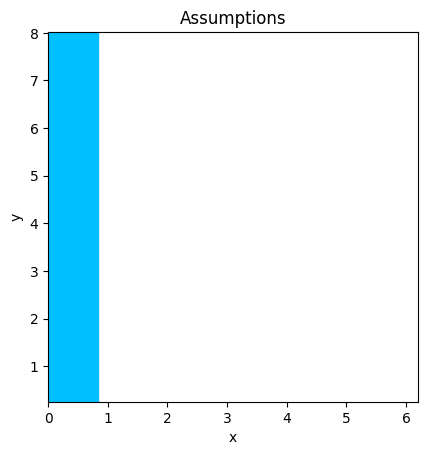

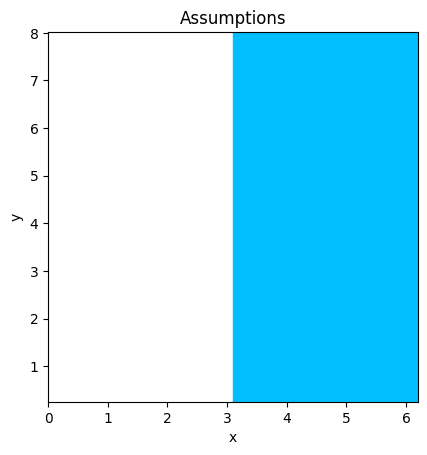

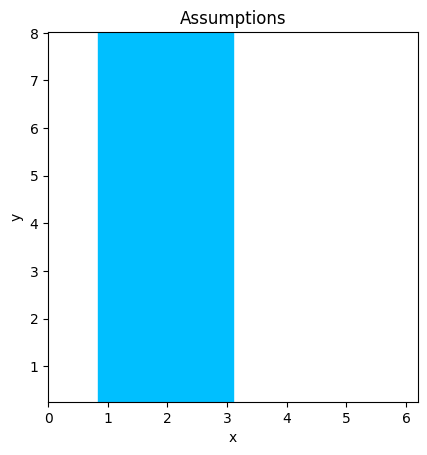

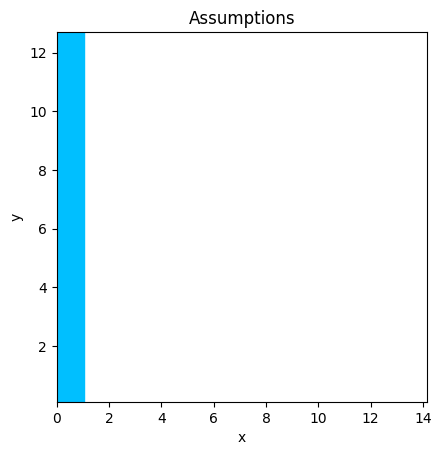

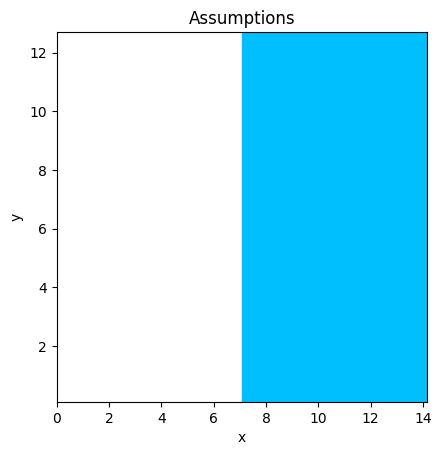

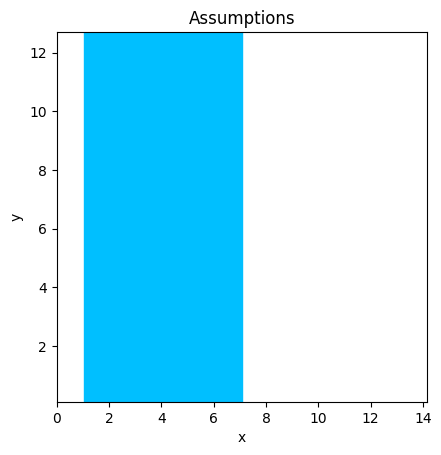

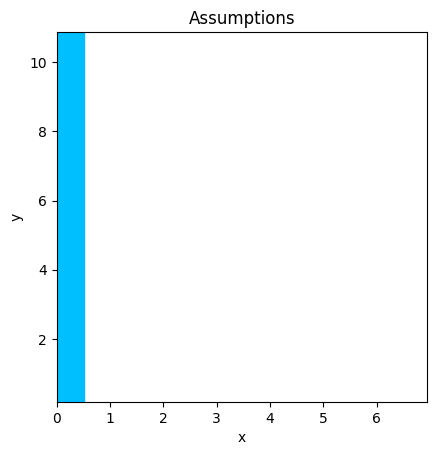

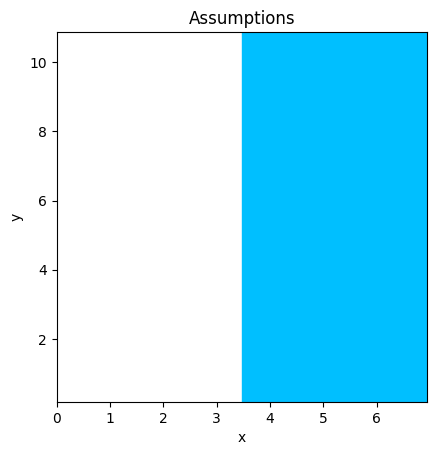

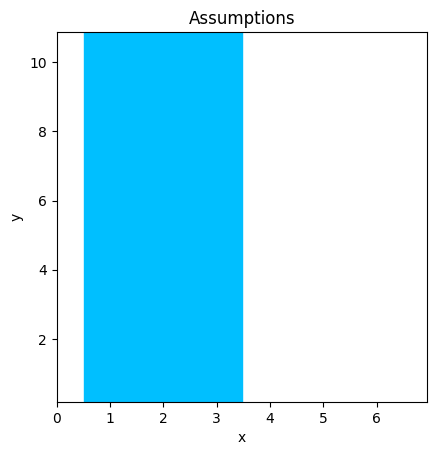

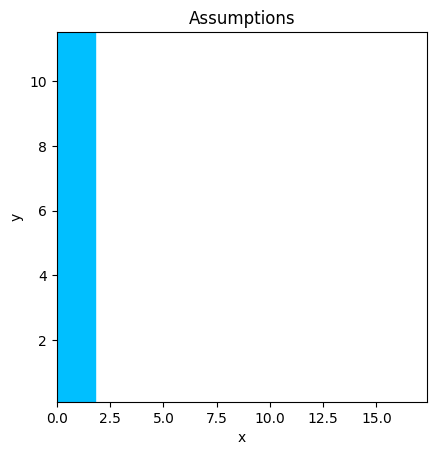

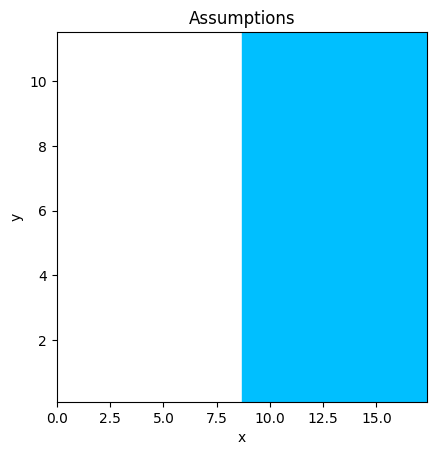

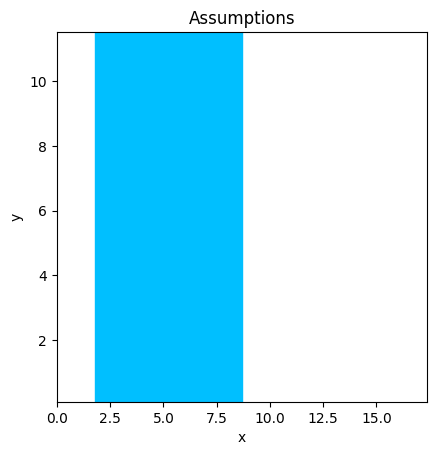

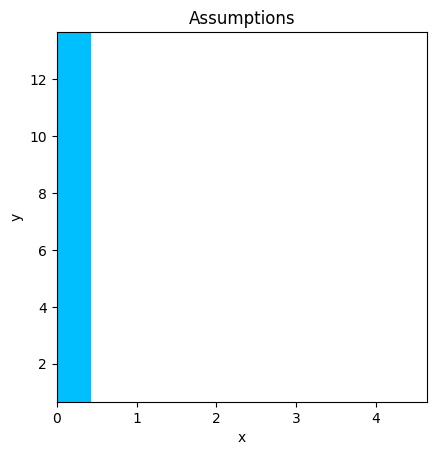

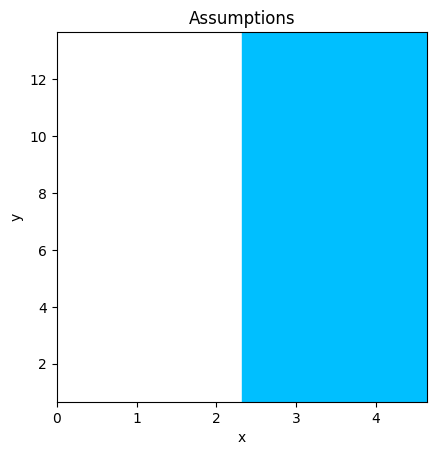

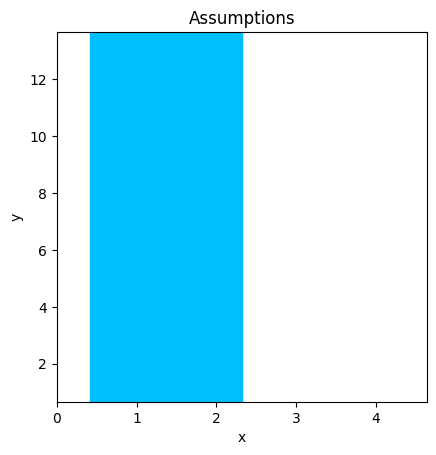

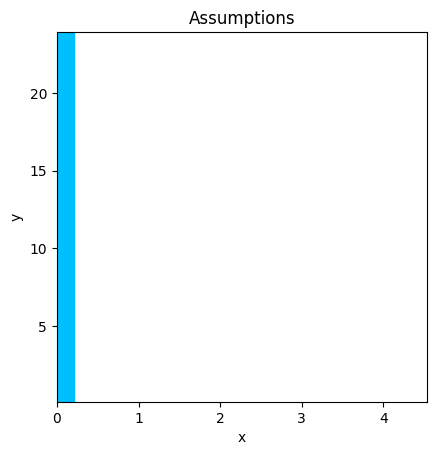

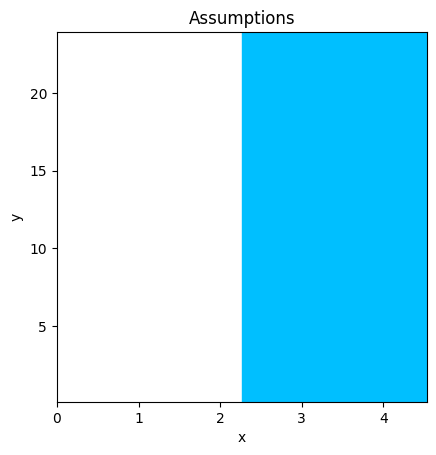

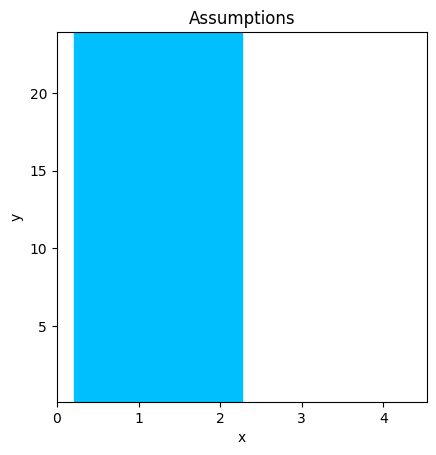

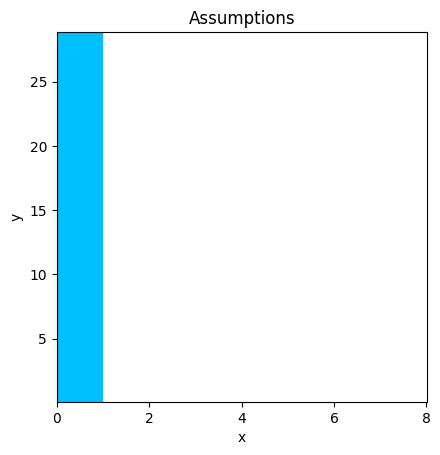

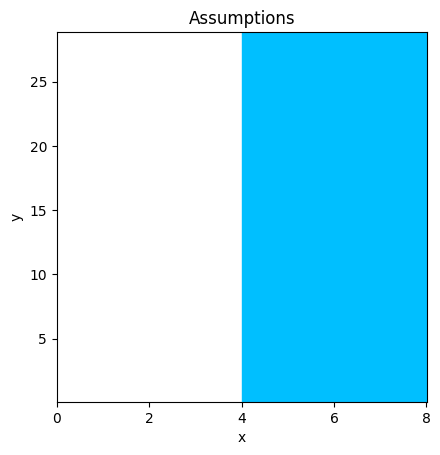

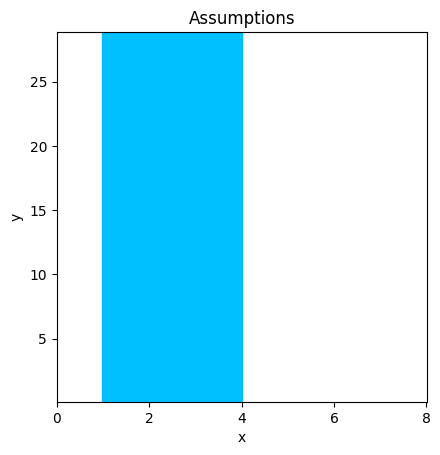

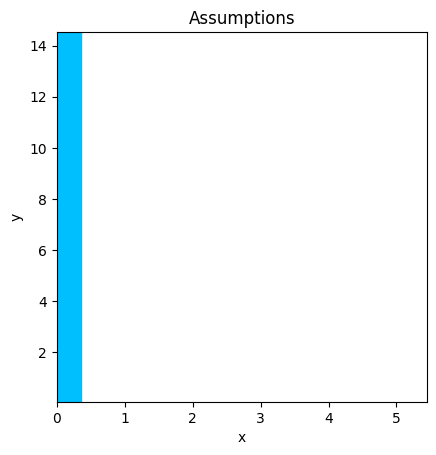

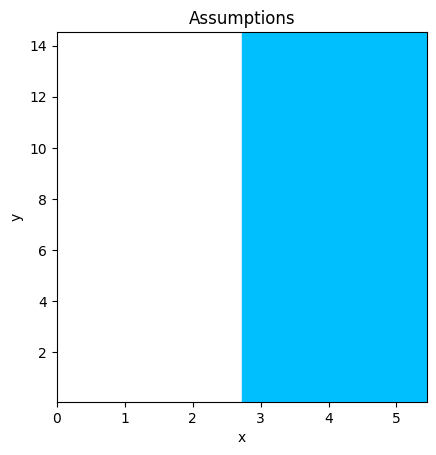

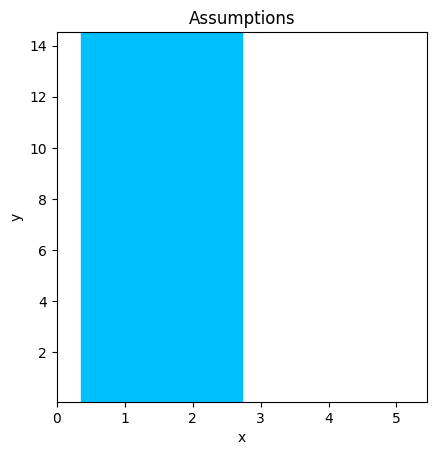

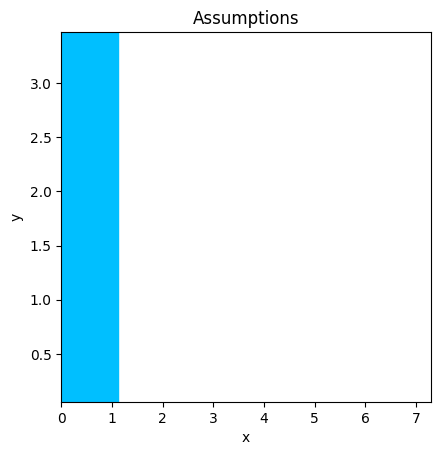

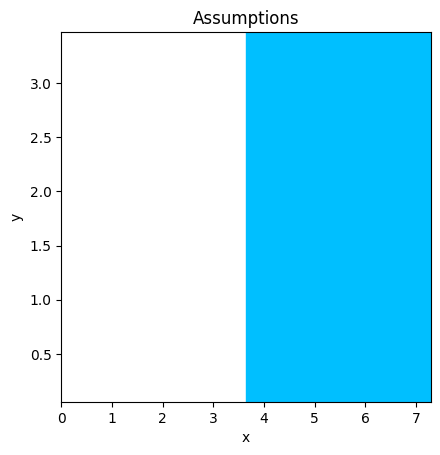

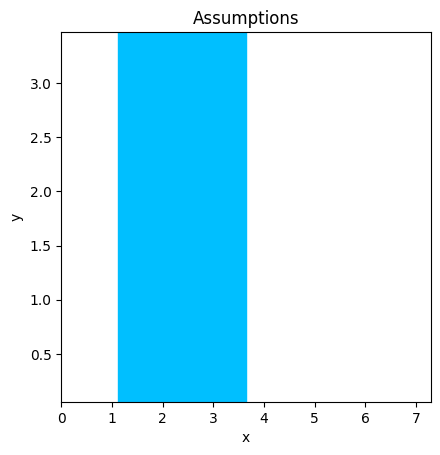

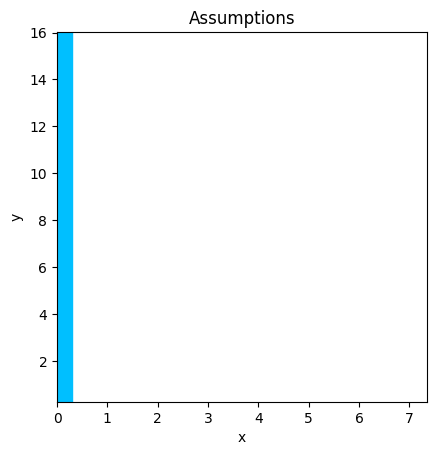

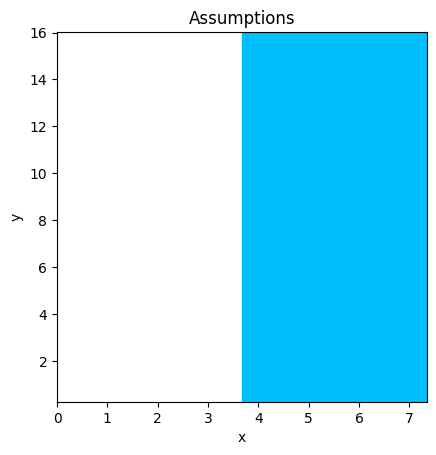

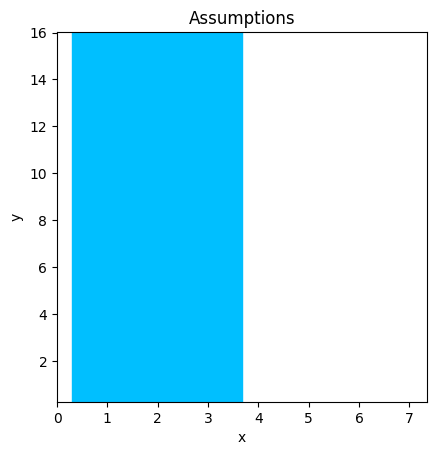

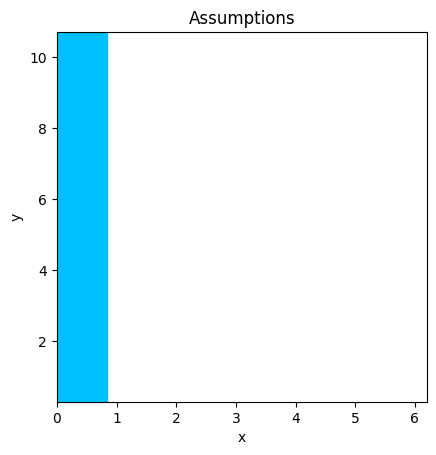

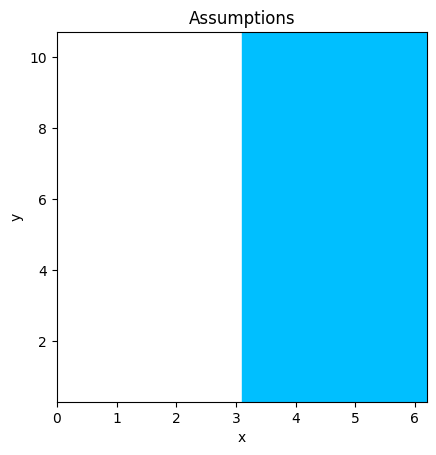

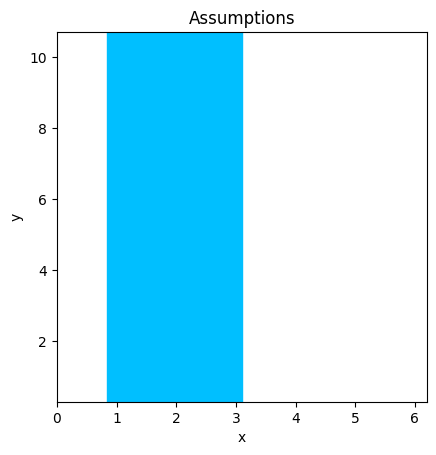

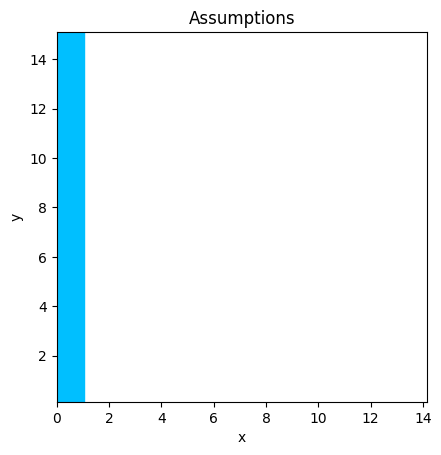

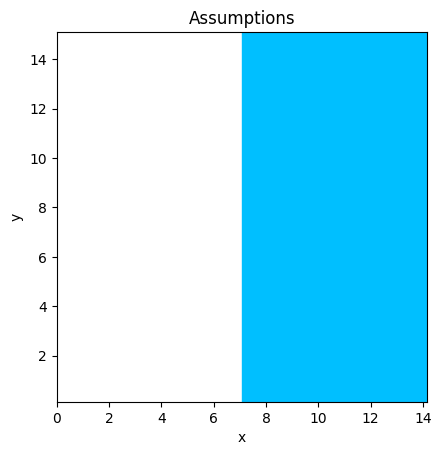

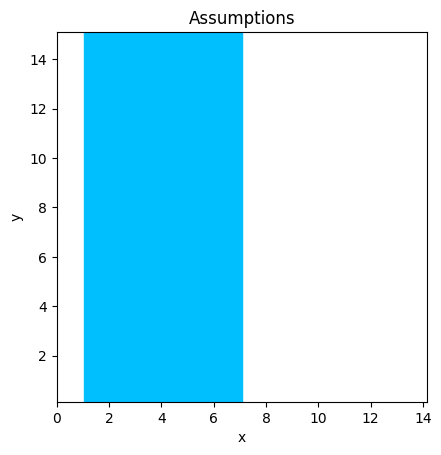

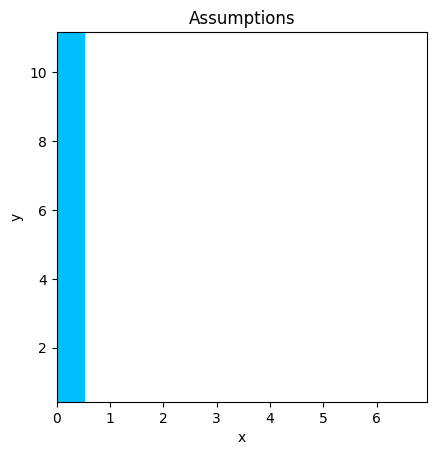

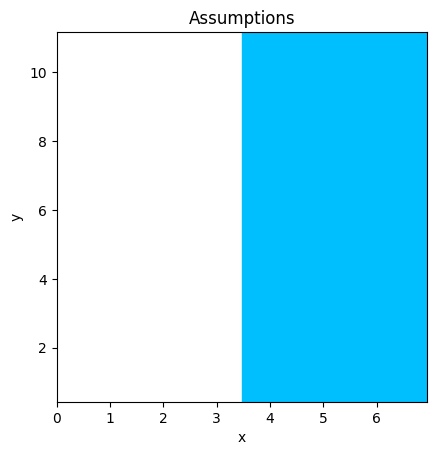

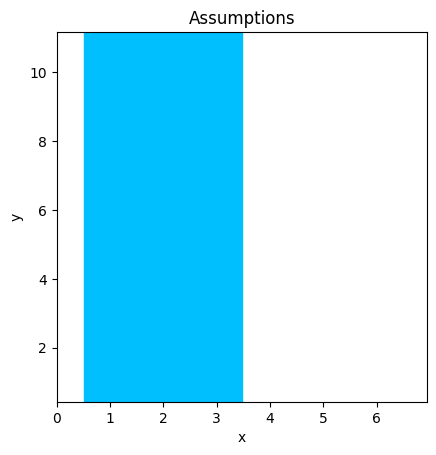

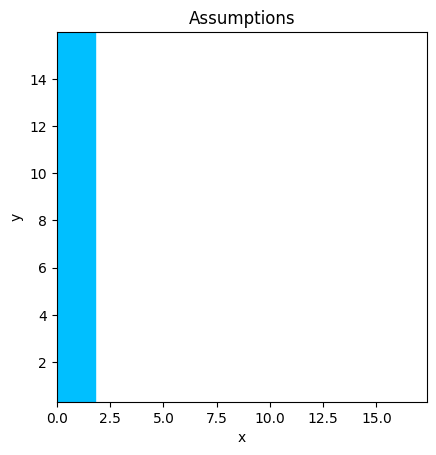

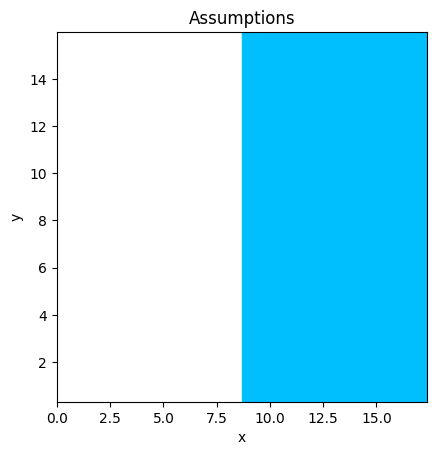

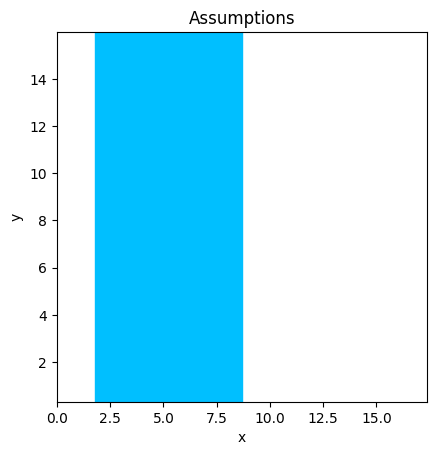

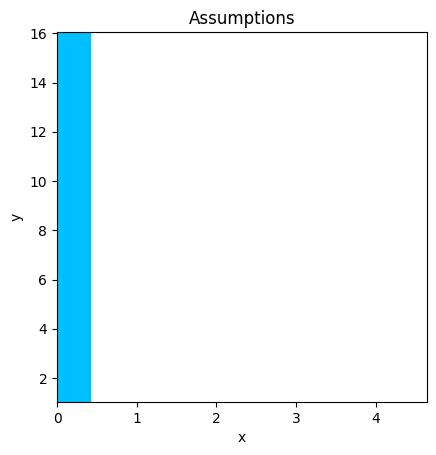

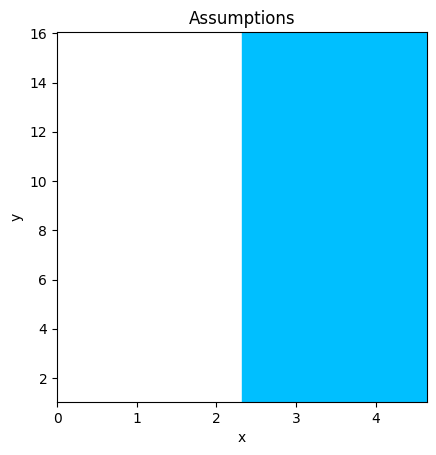

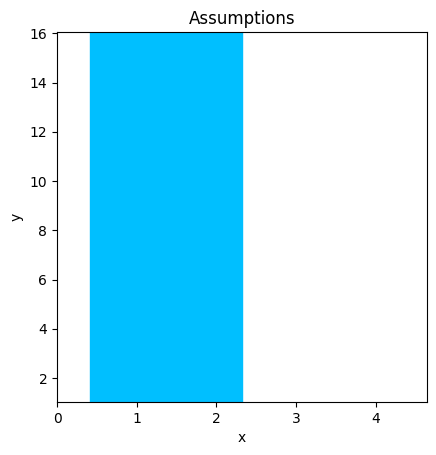

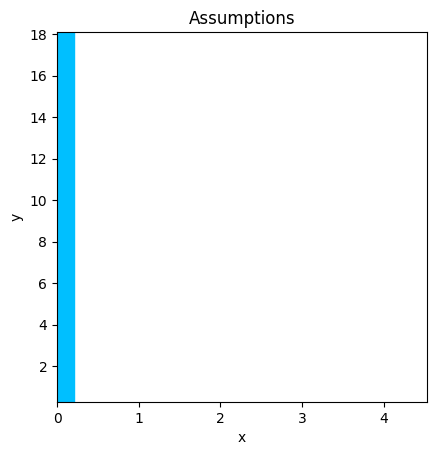

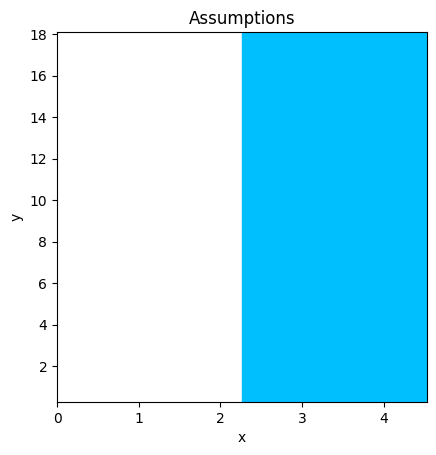

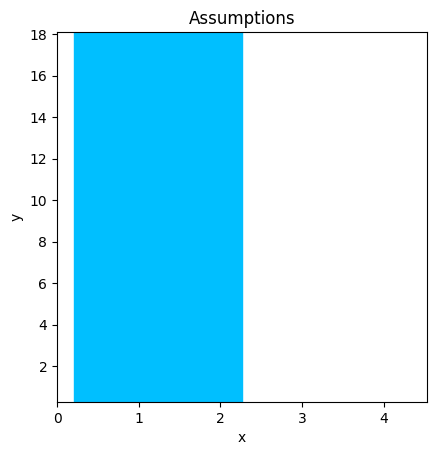

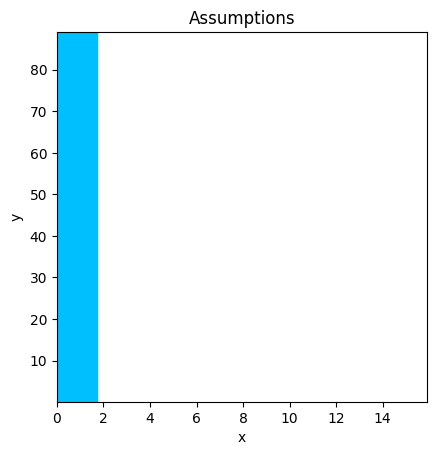

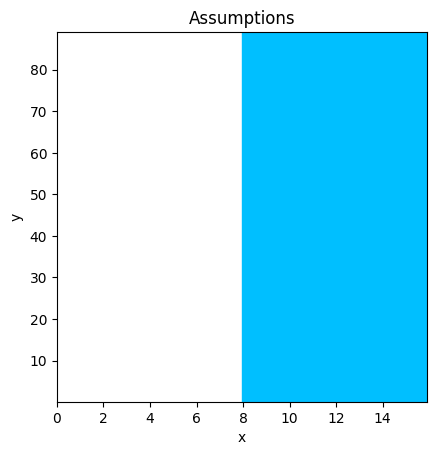

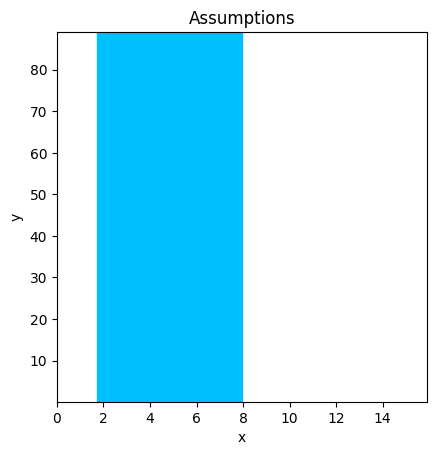

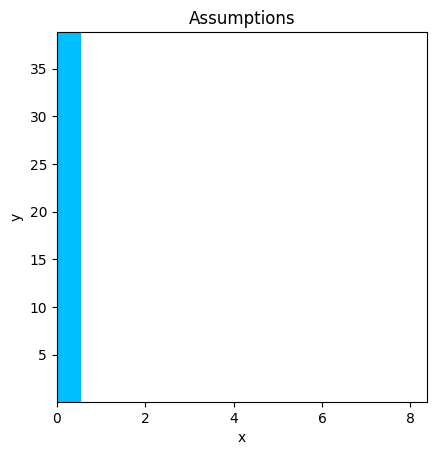

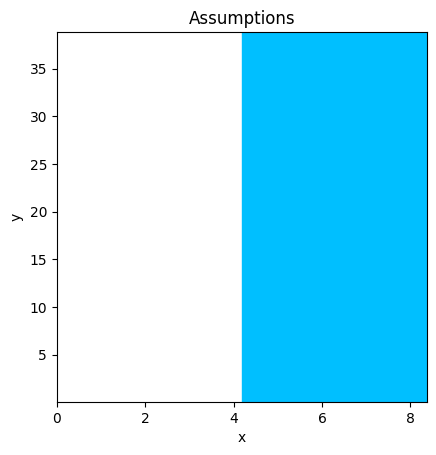

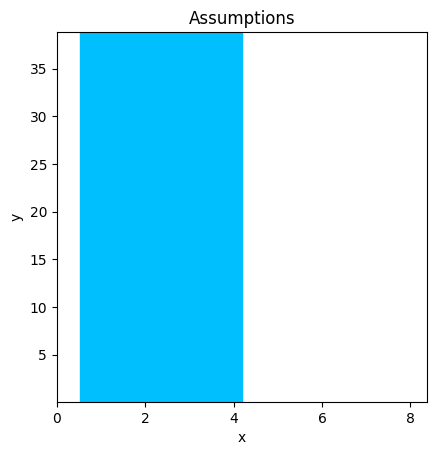

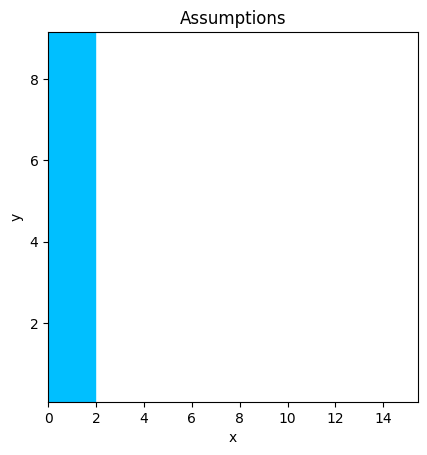

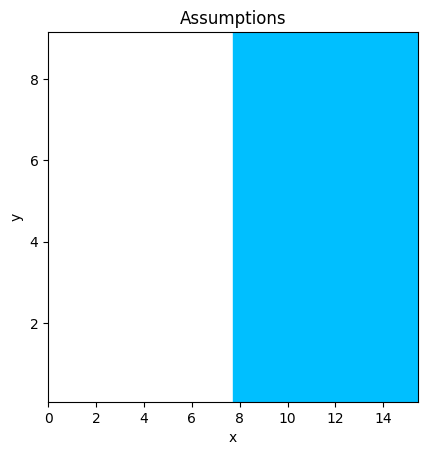

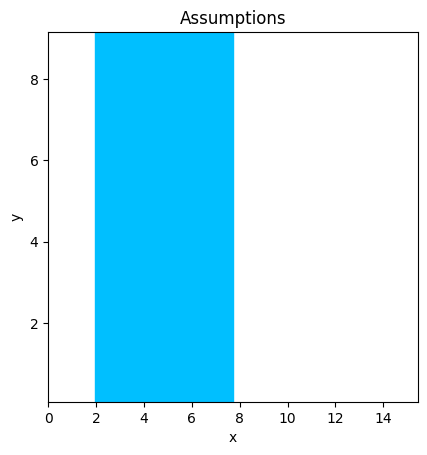

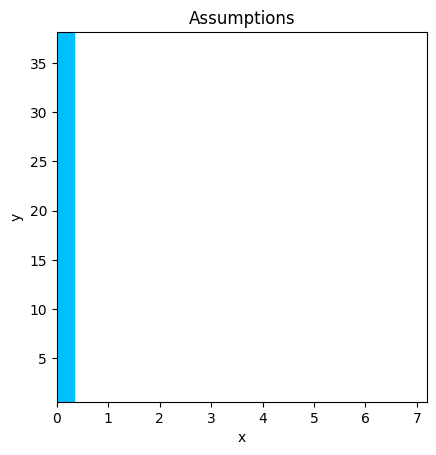

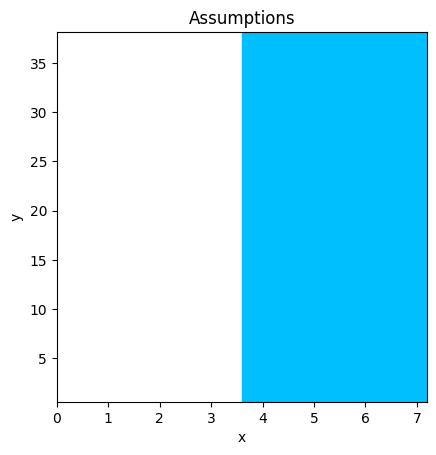

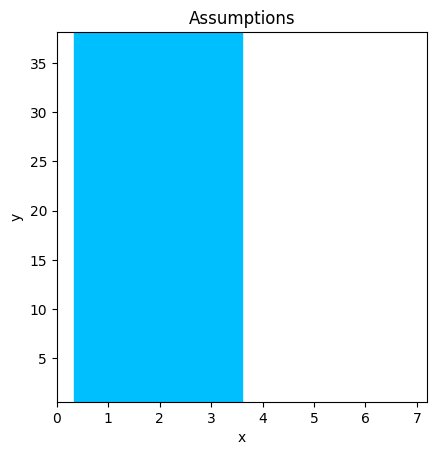

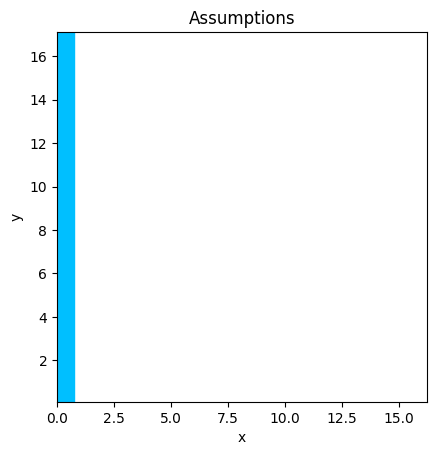

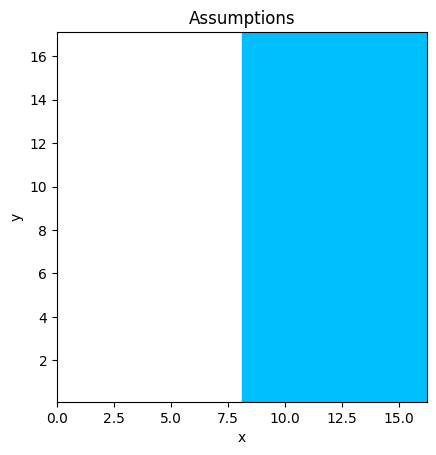

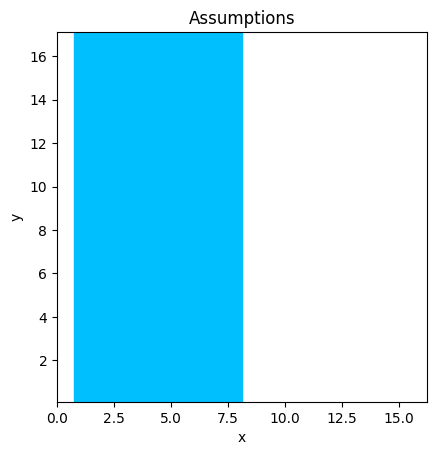

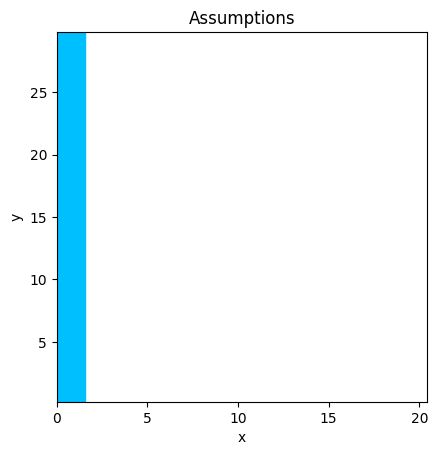

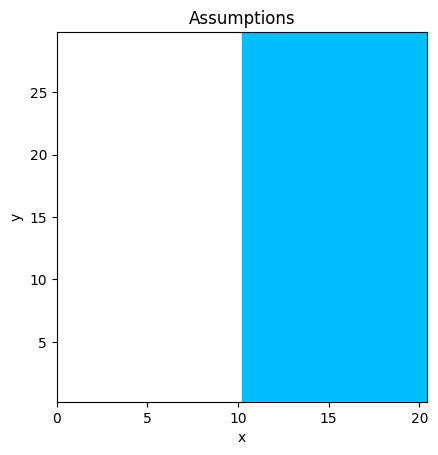

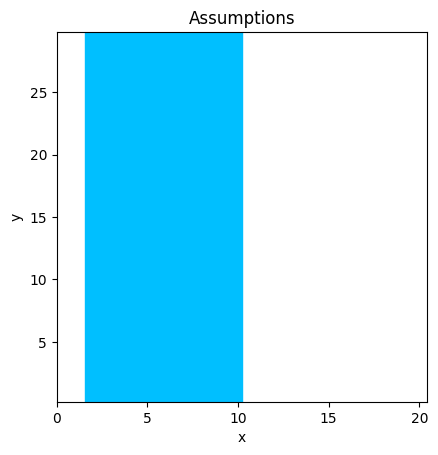

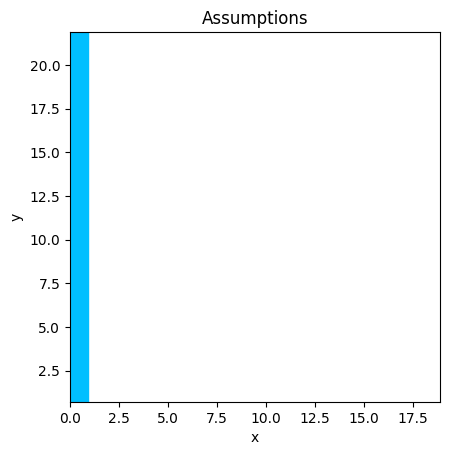

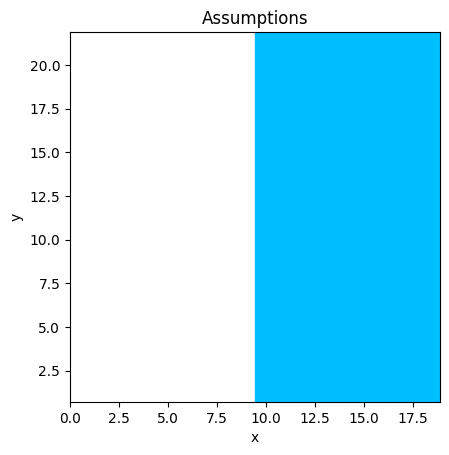

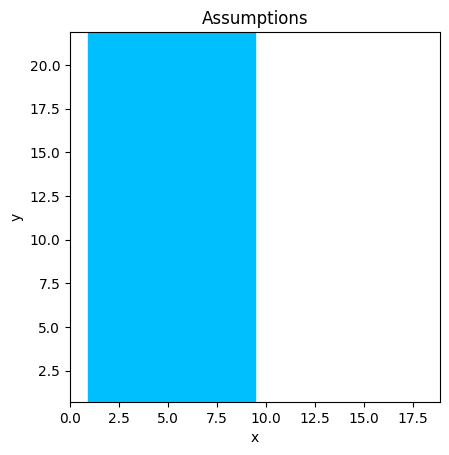

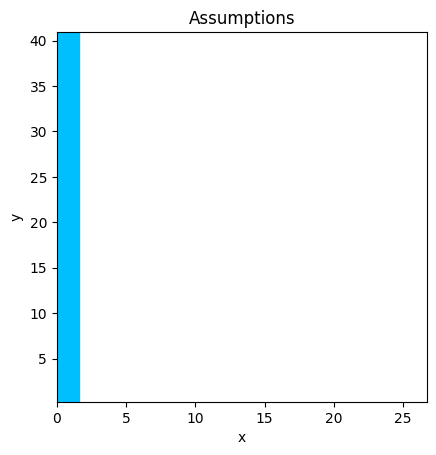

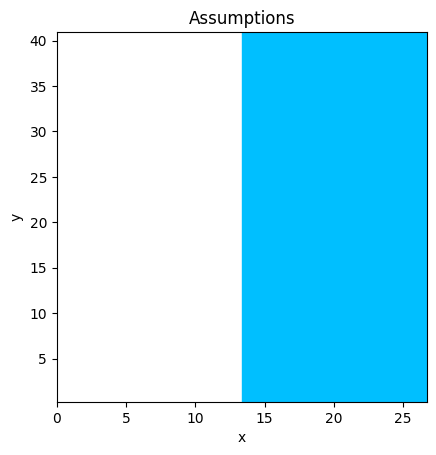

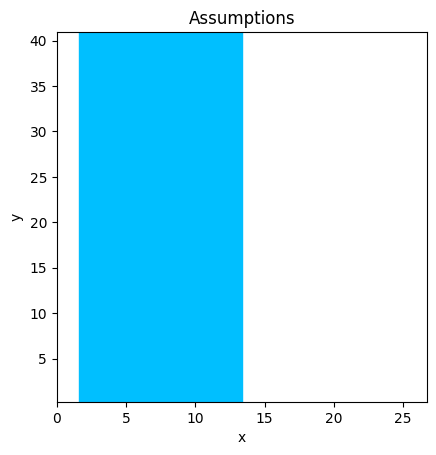

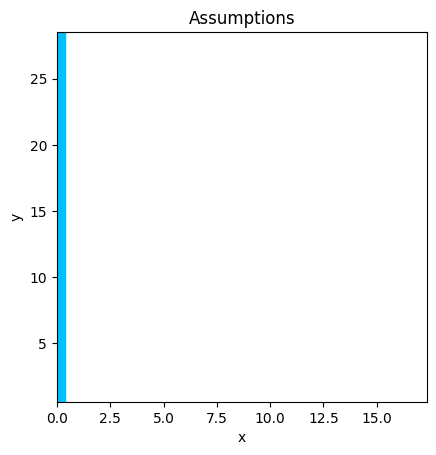

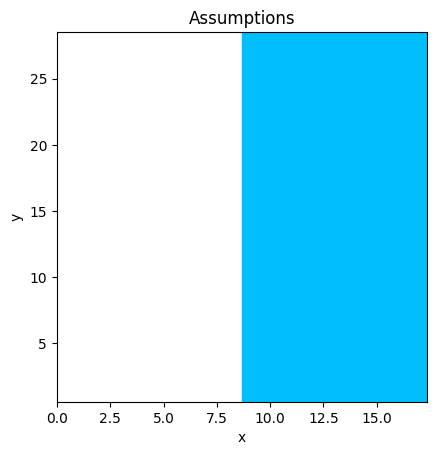

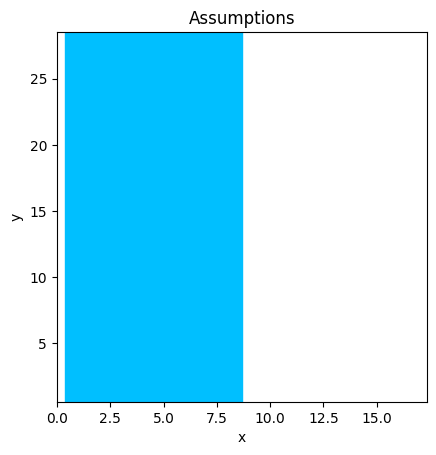

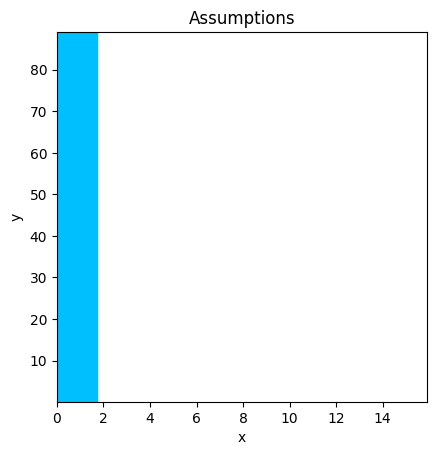

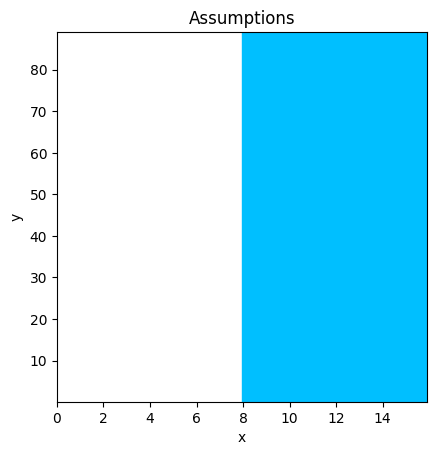

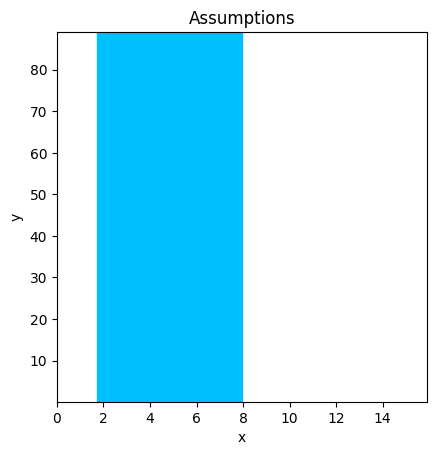

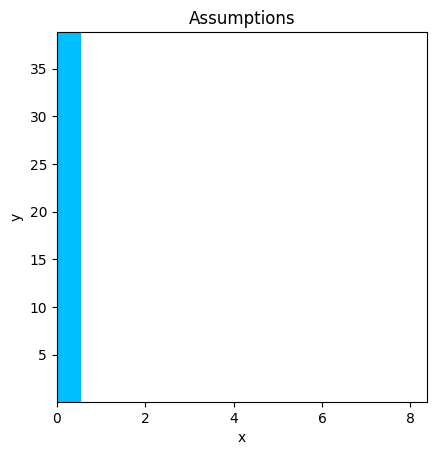

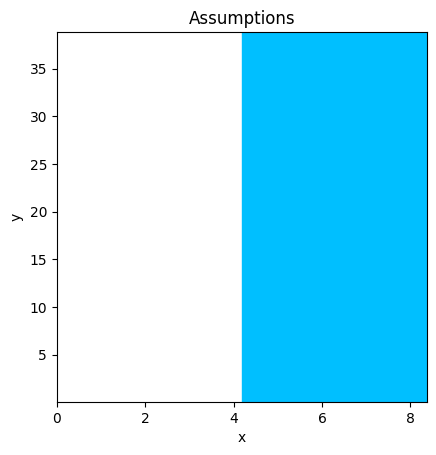

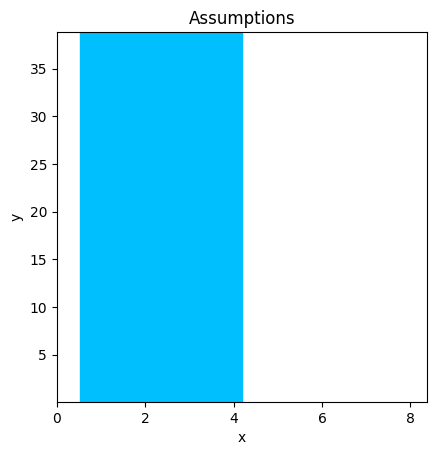

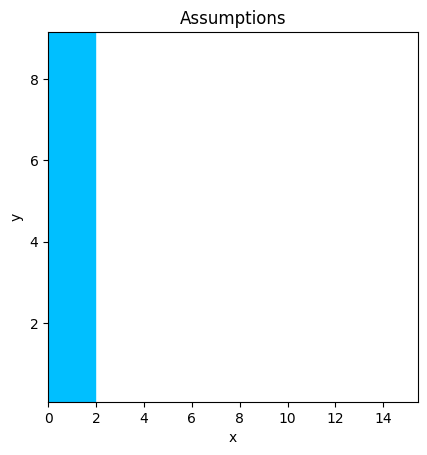

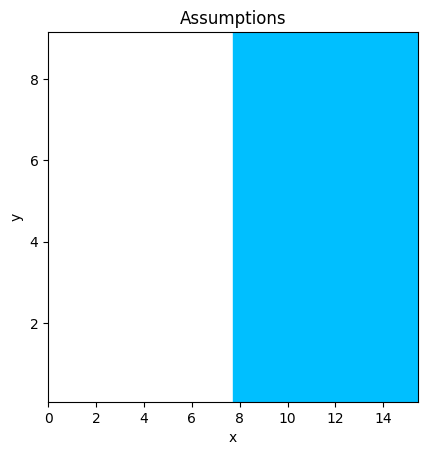

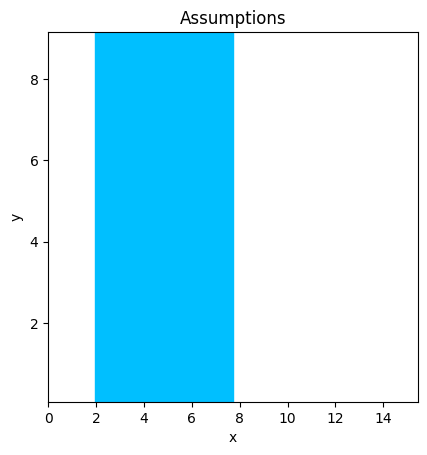

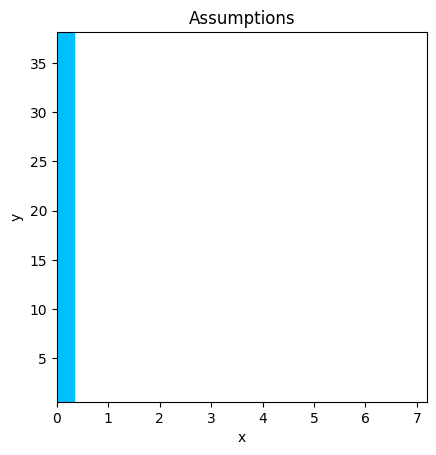

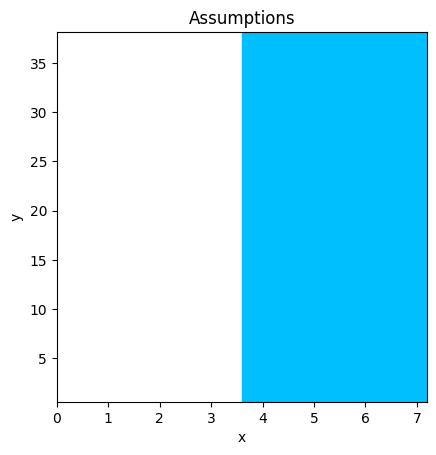

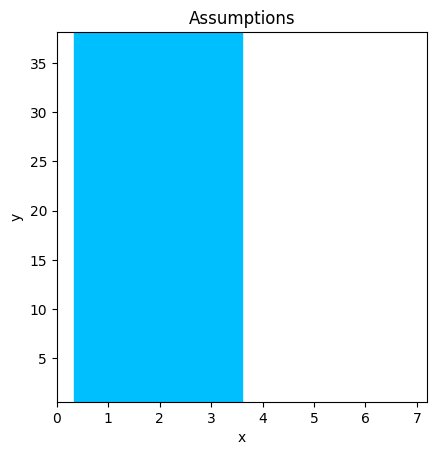

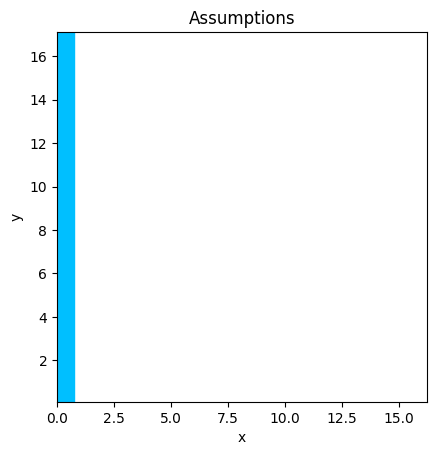

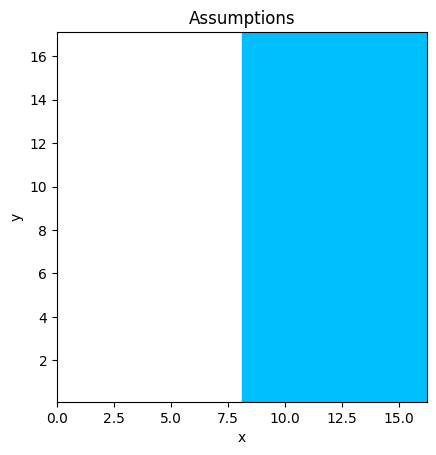

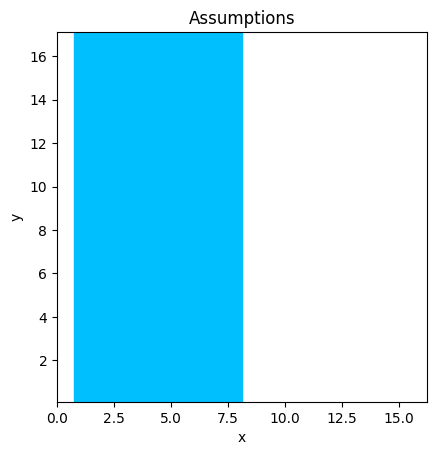

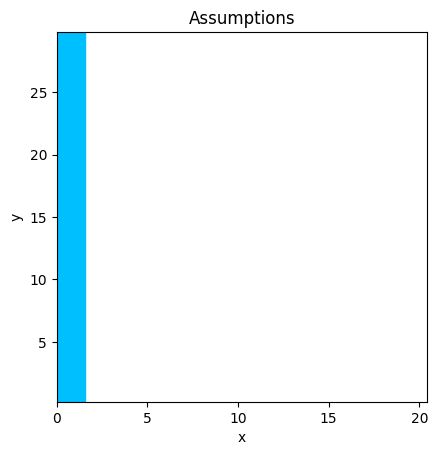

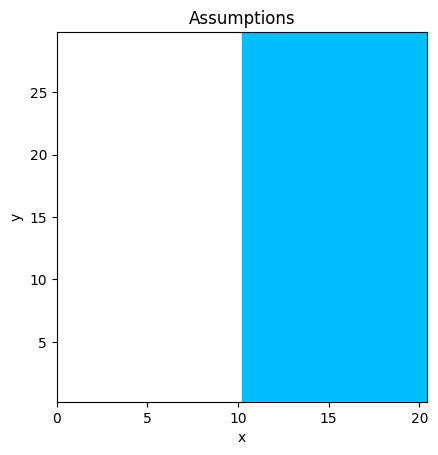

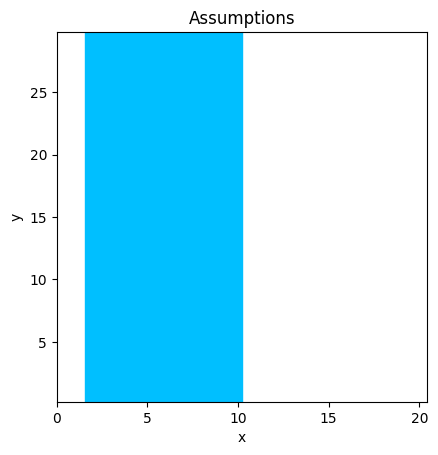

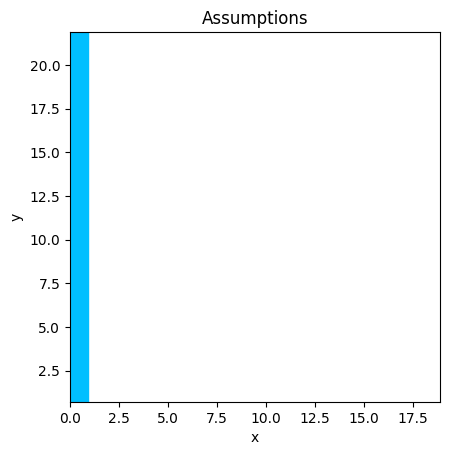

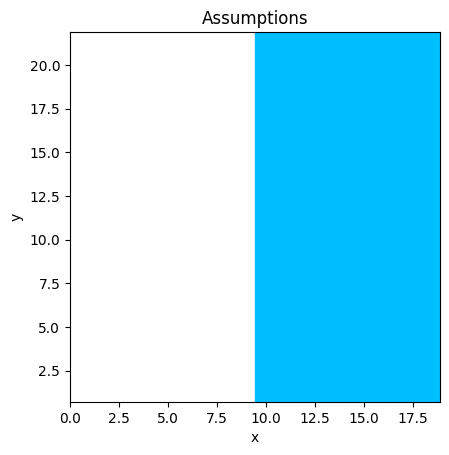

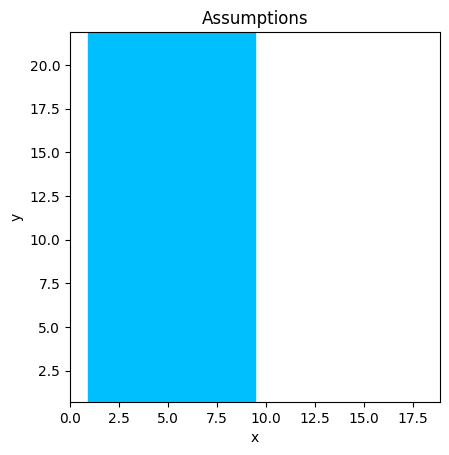

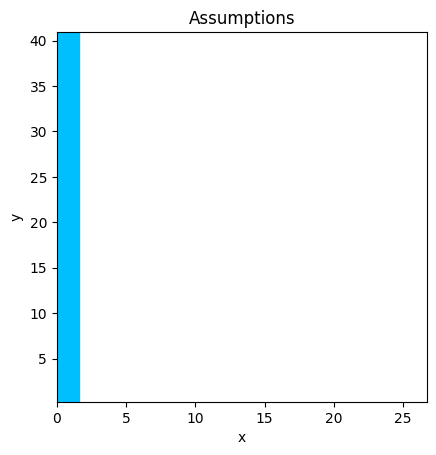

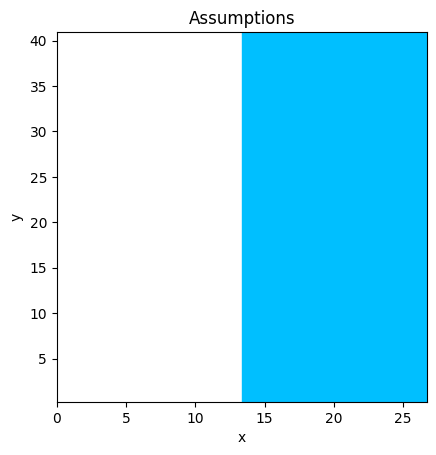

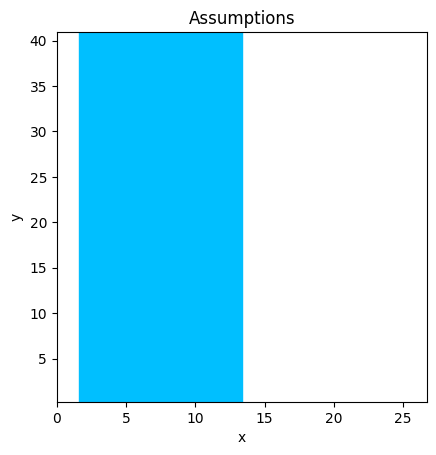

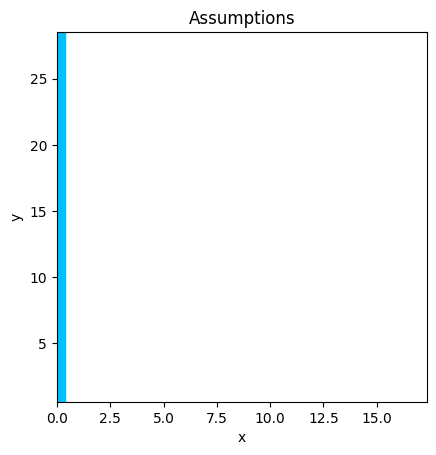

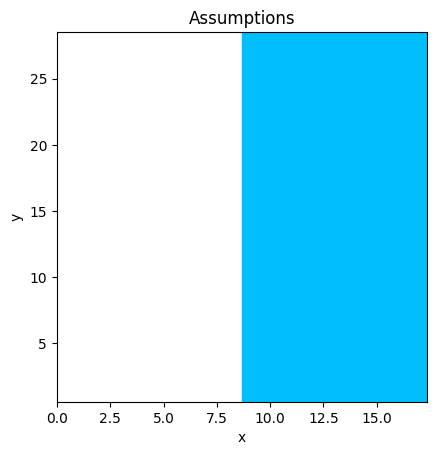

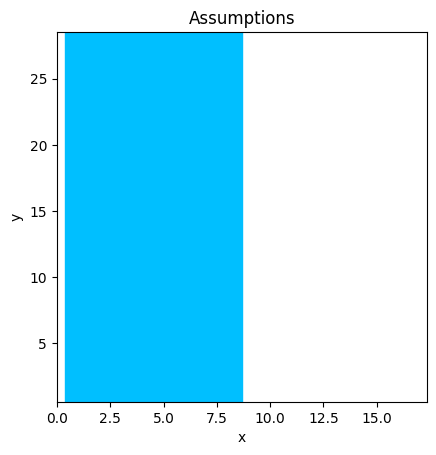

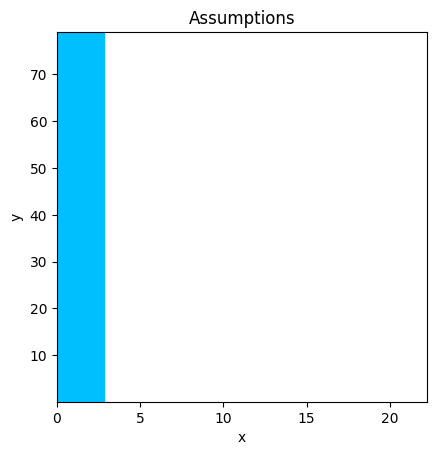

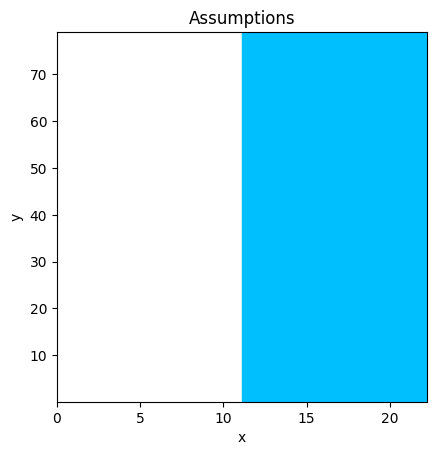

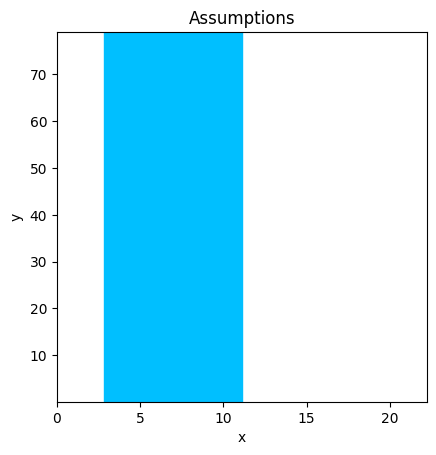

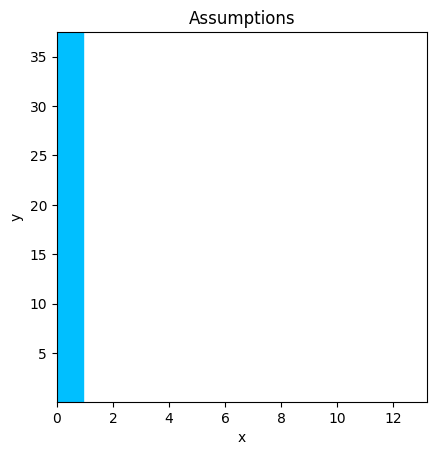

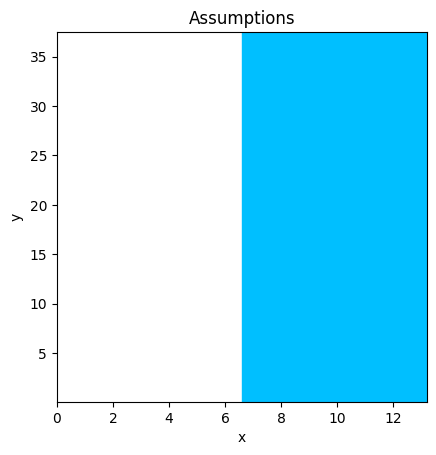

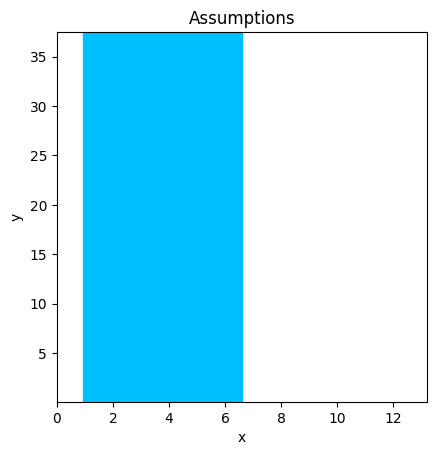

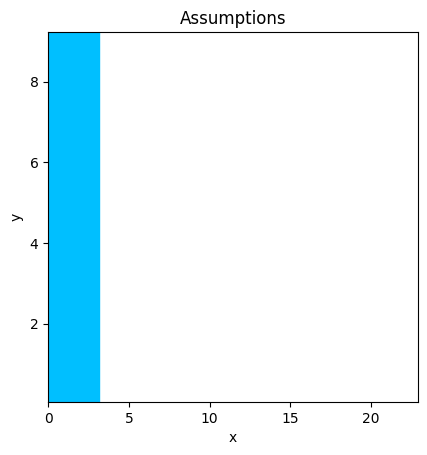

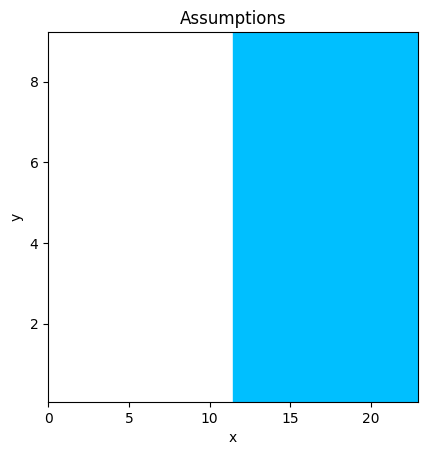

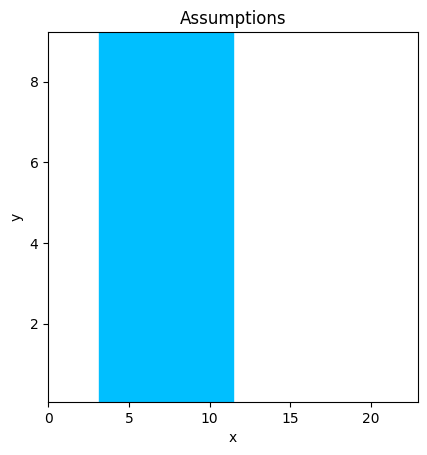

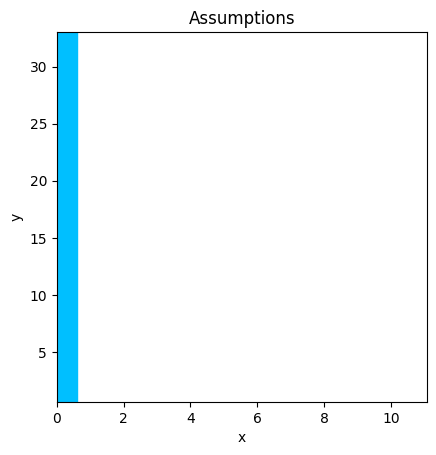

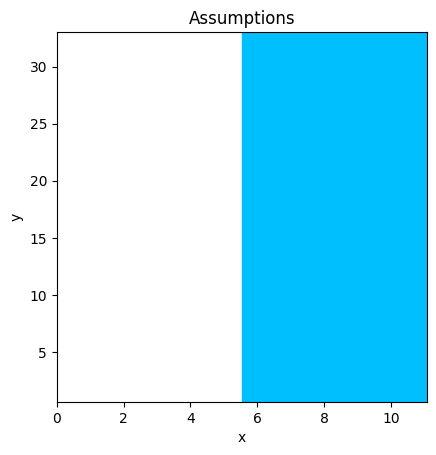

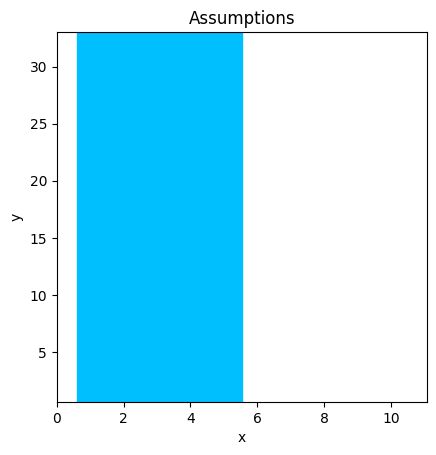

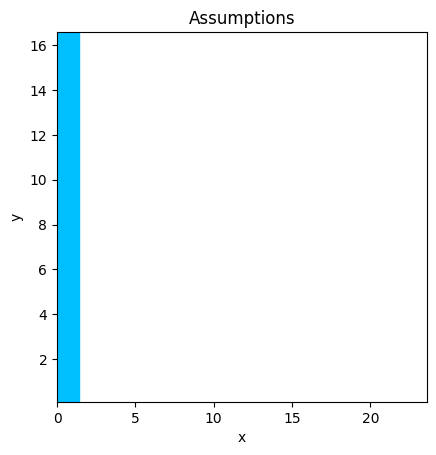

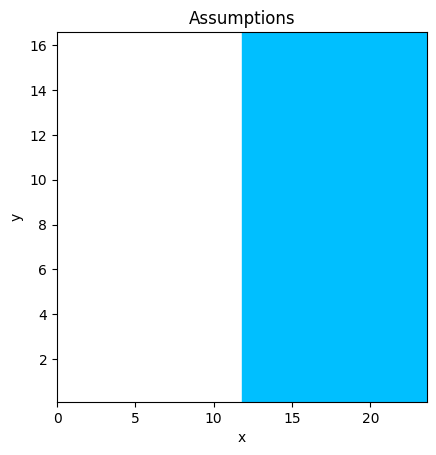

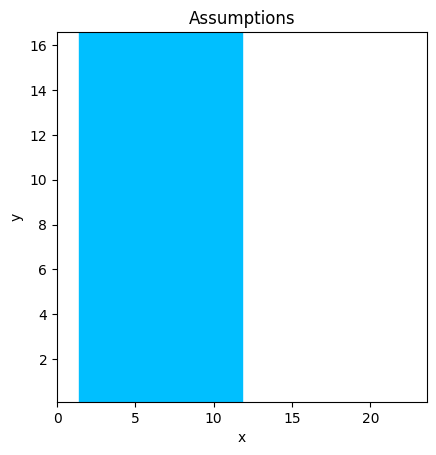

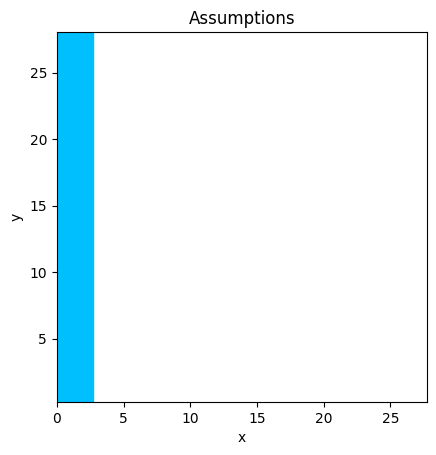

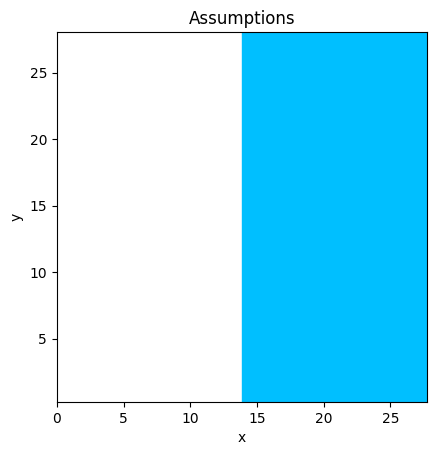

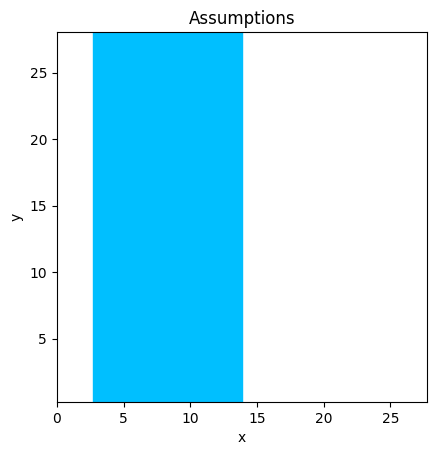

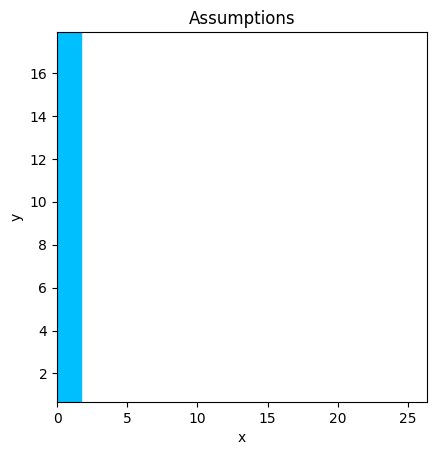

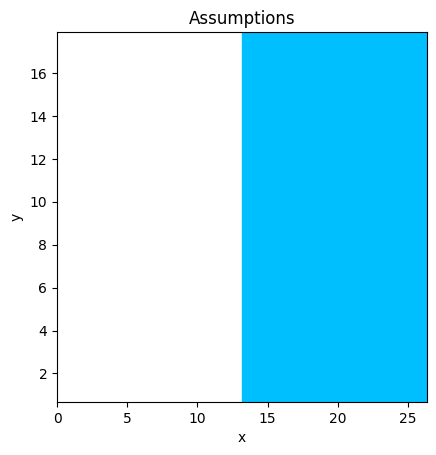

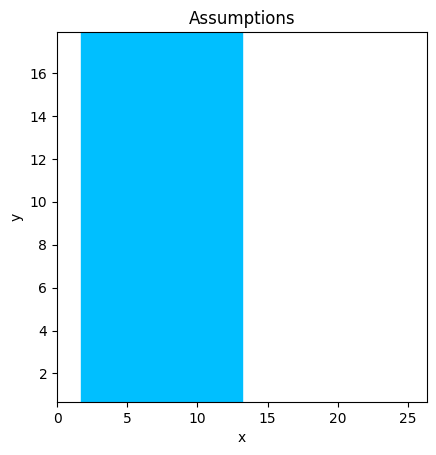

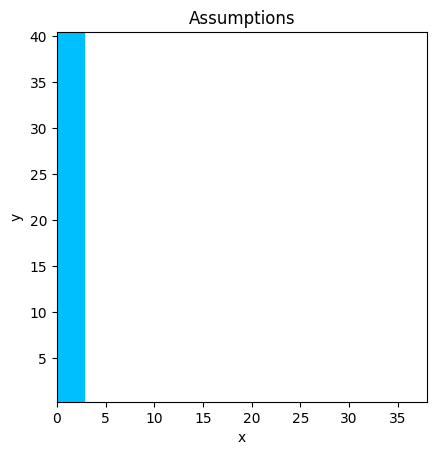

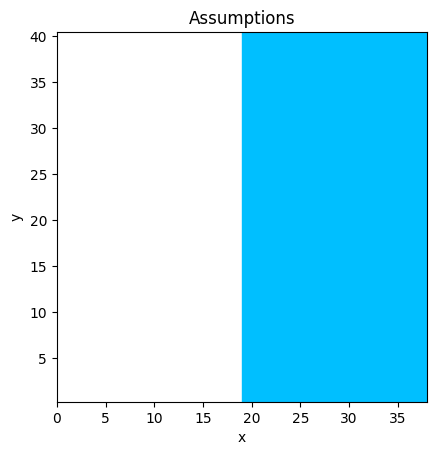

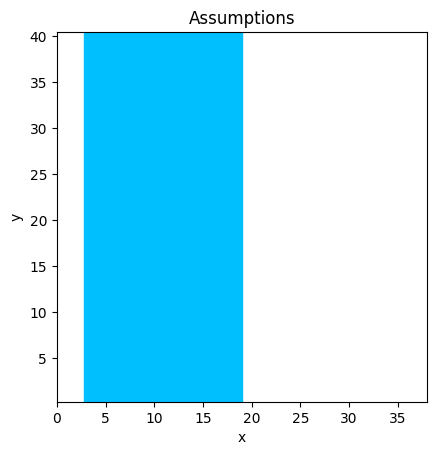

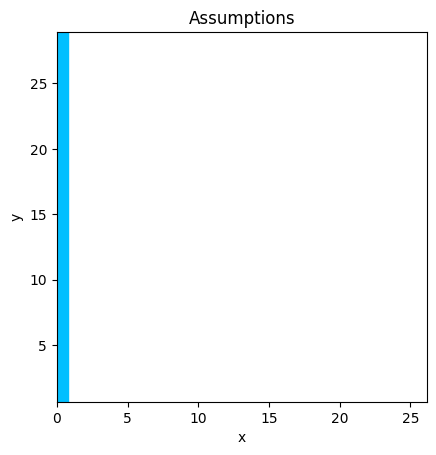

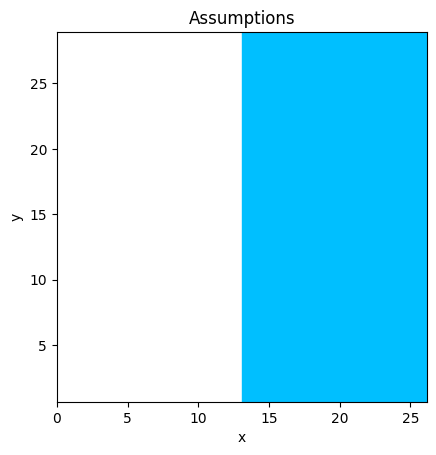

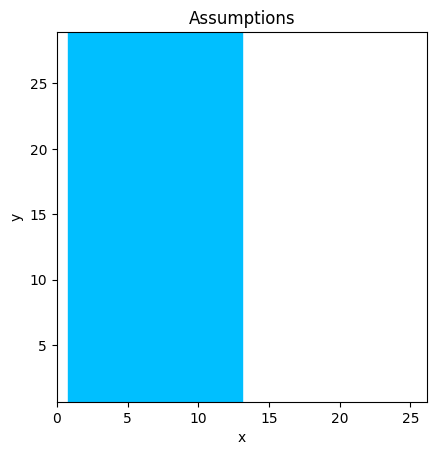

In [ ]:
import pandas as pd
from pacti.contracts import PolyhedralIoContract
from pacti.utils.plots import plot_assumptions
from pacti.utils.plots import plot_guarantees
from pathlib import Path

#to create contracts we need the IL IH: 
#structure should be as follows for a NOR gate:
# assume (x < IL)
# then gaurentee output = ON and in range [y(IL), ymax]
#assume (x > IH)
# then gaurentee output = OFF and in range [ymin, y(IH)]
#assume (IL < x < IH) 
# then gaurentee output = transition  and in range [y(IH), y(IL)]

csv_files = [
    "/home/shrut/bioCircuitProject/library/NOR_gate/parsed_Eco1C1G1T1.csv",
    "/home/shrut/bioCircuitProject/library/NOR_gate/parsed_Eco1C1G1T1b.csv", 
    "/home/shrut/bioCircuitProject/library/NOR_gate/parsed_EcoCB1_v1.csv",
    "/home/shrut/bioCircuitProject/library/NOR_gate/parsed_EcoCB1_v2.csv",
    "/home/shrut/bioCircuitProject/library/NOR_gate/parsed_EcoCB1.csv",
    "/home/shrut/bioCircuitProject/library/NOR_gate/parsed_EcoJS4ib_110215.csv",
    "/home/shrut/bioCircuitProject/library/NOR_gate/parsed_EcoJS4ib_111015.csv",
    "/home/shrut/bioCircuitProject/library/NOR_gate/parsed_EcoJS4ib.csv",
]

csv_files_names = [
    "parsed_Eco1C1G1T1.csv",
    "parsed_Eco1C1G1T1b.csv",
    "parsed_EcoCB1_v1.csv",
    "parsed_EcoCB1_v2.csv",
    "parsed_EcoCB1.csv",
    "parsed_EcoJS4ib_110215.csv",
    "parsed_EcoJS4ib_111015.csv",
    "parsed_EcoJS4ib.csv",
]

# df = pd.read_csv(csv_files[0])

#to be able to figure out corresponding y values for given x values (IL and IH are x values)
#also important because contracts say assuming x is in a certain range, then y is guaranteed to be in a certain range 
def corresponding_y(x, row):
    ymin = float(row["ymin"])
    ymax = float(row["ymax"])
    k = float(row["K"])
    n = float(row["n"])
    return ymin + (ymax - ymin) / (1.0 + (x / k) ** n)

def make_nor_contracts(row):
    #contracts are based on these two x - values 
    il = float(row["IL"])
    ih = float(row["IH"])

    if il >= ih:
        raise ValueError(f"Expected IL < IH; got IL={il}, IH={ih}")

    #need corresponding y values for the regions defined by IL and IH (for the gaurentee part of the contract)

    y_at_il = corresponding_y(il, row)
    y_at_ih = corresponding_y(ih, row)
    ymin = float(row["ymin"])
    ymax = float(row["ymax"])



    # [y(IL), ymax] -> range of y values for: x < IL -> ON
    # [y(IL), y(IH)] -> range of y values for: IL < x < IH -> transition
    # [ymin, y(IH)] -> range of y values for: x > IH -> OFF

    #returns dictionary of three contracts PER row 
    return {
        "ON": PolyhedralIoContract.from_strings(
            input_vars=["x"],
            output_vars=["y"],

            assumptions=["-x <= 0", f"x <= {il:.12g}"], #negating both sides reverses ineqality 
            guarantees=[f"-y <= {-y_at_il:.12g}", f"y <= {ymax:.12g}"],
        ),
        "transition": PolyhedralIoContract.from_strings(
            input_vars=["x"],
            output_vars=["y"],
            assumptions=[f"-x <= {-il:.12g}", f"x <= {ih:.12g}"],
            guarantees=[f"-y <= {-y_at_ih:.12g}", f"y <= {y_at_il:.12g}"],
        ),
        "OFF": PolyhedralIoContract.from_strings(
            input_vars=["x"],
            output_vars=["y"],
            assumptions=[f"-x <= {-ih:.12g}"],
            guarantees=[f"-y <= {-ymin:.12g}", f"y <= {y_at_ih:.12g}"],
        ),
    }

#organizing dictionary by file name and protien name 
contracts = {}
for file_name, csv_path in zip(csv_files_names, csv_files):
    contracts[file_name] = {}
    df = pd.read_csv(csv_path)
    for i, row in df.iterrows():
        protein_name = str(row["name"])
        # need to double check that none of the files have multiple graphs w same protien name not sure if itll overwrite 
        # if protein_name in contracts[file_name]:
        #     print(f" Multiple entries found for protein '{protein_name}' in file '{file_name}'")
        contracts[file_name][protein_name] = make_nor_contracts(row)
        #check if the contracts are correct by using plot_assumptions and plot_garantees functions
        x_max = (2.0 * float(row["IH"]))  # setting x_max to twice the IH value for plotting 
        plot_assumptions(contract=contracts[file_name][protein_name]["ON"], x_var="x", y_var="y",var_values={}, x_lims=(0.0, x_max),y_lims=(float(row["ymin"]), float(row["ymax"])),show=True,)
        plot_assumptions(contract=contracts[file_name][protein_name]["OFF"], x_var="x", y_var="y",var_values={}, x_lims=(0.0, x_max),y_lims=(float(row["ymin"]), float(row["ymax"])),show=True,)
        plot_assumptions(contract=contracts[file_name][protein_name]["transition"], x_var="x", y_var="y",var_values={}, x_lims=(0.0, x_max),y_lims=(float(row["ymin"]), float(row["ymax"])),show=True,)
        


# for i in range(len(df)):
#     protein_name = str(df.iloc[i]["name"])
#     print(contracts[protein_name]["ON"])
#     print(contracts[protein_name]["OFF"])
#     print(contracts[protein_name]["transition"])
